# SUPER TOPIC 1 - Adult Income Data Mining\nSource: 1.Data Mining/adult_data_analysis.ipynb\n

# تحلیل آماری مجموعه‌داده Adult
این نوت‌بوک تمرین‌های خواسته‌شده را به‌صورت خلاصه، همراه با توضیح و نمودار اجرا می‌کند. نام ستون‌ها مطابق فایل اصلی Adult است. در Colab، فایل `adult.csv` را در همان محیط آپلود کنید و سپس سلول بارگذاری را اجرا کنید. شماره‌ردیف‌های ذکرشده در محاسبات، **اندیس صفرمبنا** هستند.


In [4]:
# ۱) کتابخانه‌ها و بارگذاری داده
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import euclidean, cityblock

# اگر فایل کنار نوت‌بوک نیست (مثلاً در Colab)، آن را انتخاب و آپلود کنید.
DATA_PATH = "/content/drive/MyDrive/Colab Notebooks/adult.csv"
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError("adult.csv را در پوشهٔ جاری قرار دهید.")

# Adult اصلی از کاما و فاصلهٔ اضافی در مقادیر متنی استفاده می‌کند.
df = pd.read_csv(DATA_PATH, skipinitialspace=True)
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include="object"):
    df[col] = df[col].str.strip()
# علامت ? در نسخهٔ اصلی به معنی مقدار ناموجود است.
df = df.replace("?", np.nan)
print(f"ابعاد داده: {df.shape}")
display(df.head(3))


ابعاد داده: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capitalGain,capitalLoss,hoursPerWeek,nativeCountry,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## ۲) داده‌های پرت `education-num` با معیار ۱٫۵×IQR


Q1=9, Q3=12, IQR=3; حدود=[4.5, 16.5]
تعداد پرت: 1,198 از 32,561 (3.68٪)


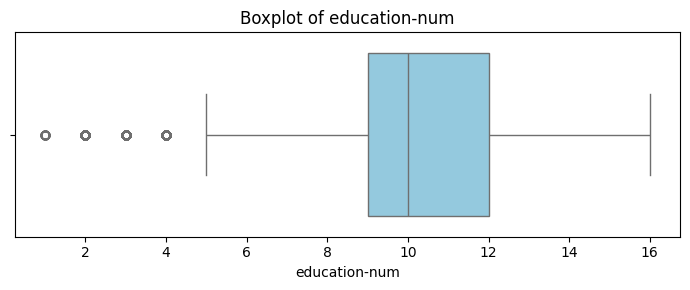

In [5]:
# هر مقدار بیرون از بازهٔ [Q1−1.5×IQR, Q3+1.5×IQR] پرت شمرده می‌شود.
col = "education-num"
x = df[col].dropna()
q1, q3 = x.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = x[(x < lo) | (x > hi)]
print(f"Q1={q1:g}, Q3={q3:g}, IQR={iqr:g}; حدود=[{lo:g}, {hi:g}]")
print(f"تعداد پرت: {len(outliers):,} از {len(x):,} ({len(outliers)/len(x)*100:.2f}٪)")
plt.figure(figsize=(7, 3))
sns.boxplot(x=x, color="skyblue")
plt.title("Boxplot of education-num")
plt.xlabel("education-num")
plt.tight_layout()
plt.show()


## ۳) نمودار Q–Q سن در دو گروه درآمدی
هر نمودار توزیع سن در گروه مربوطه را با توزیع نرمال مقایسه می‌کند.


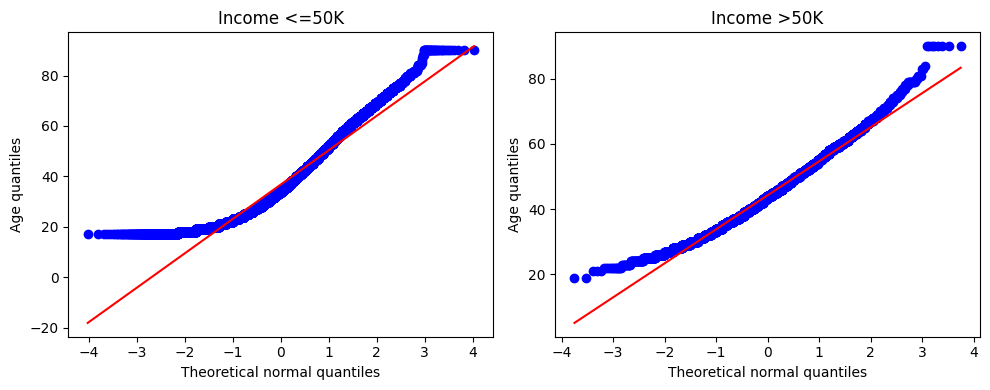

In [6]:
# برچسب درآمد و سن را پاک‌سازی‌شده و بدون مقدار ناموجود انتخاب می‌کنیم.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, label, title in zip(axes, ["<=50K", ">50K"], ["Income <=50K", "Income >50K"]):
    ages = df.loc[df["income"] == label, "age"].dropna()
    stats.probplot(ages, dist="norm", plot=ax)
    ax.set_title(title)
    ax.set_xlabel("Theoretical normal quantiles")
    ax.set_ylabel("Age quantiles")
plt.tight_layout()
plt.show()


## ۴) فاصلهٔ اقلیدسی و منهتن برای ردیف‌های ۲۷ و ۸۱
محاسبه روی `age`، `hoursPerWeek` و `education-num` انجام می‌شود. استانداردسازی Z با میانگین و انحراف معیار کل داده انجام شده است.


In [7]:
# iloc به‌صراحت ردیف‌های با اندیس صفرمبنای ۲۷ و ۸۱ را برمی‌گزیند.
features = ["age", "hoursPerWeek", "education-num"]
points = df[features].astype(float)
a, b = points.iloc[27].to_numpy(), points.iloc[81].to_numpy()
raw = (euclidean(a, b), cityblock(a, b))
scaled = (points - points.mean()) / points.std(ddof=1)
za, zb = scaled.iloc[27].to_numpy(), scaled.iloc[81].to_numpy()
zscore = (euclidean(za, zb), cityblock(za, zb))
print(f"ردیف ۲۷: {a}; ردیف ۸۱: {b}")
print(f"خام — اقلیدسی: {raw[0]:.4f} | منهتن: {raw[1]:.4f}")
print(f"Z-score — اقلیدسی: {zscore[0]:.4f} | منهتن: {zscore[1]:.4f}")


ردیف ۲۷: [54. 60. 10.]; ردیف ۸۱: [52. 40. 13.]
خام — اقلیدسی: 20.3224 | منهتن: 25.0000
Z-score — اقلیدسی: 2.0012 | منهتن: 2.9325


## ۵) عدم‌شباهت اسمی برای ردیف‌های ۲ و ۴
عدم‌شباهت برابر نسبت ویژگی‌های نامتطابق از `occupation`، `marital-status` و `workclass` است.


In [8]:
# مقایسهٔ اسمی: تطابق=۰ و عدم‌تطابق=۱؛ مقدار ناموجود نیز جداگانه بررسی می‌شود.
cat_cols = ["occupation", "marital-status", "workclass"]
p2 = df.iloc[2][cat_cols]
p4 = df.iloc[4][cat_cols]
valid = p2.notna() & p4.notna()
if not valid.any():
    raise ValueError("هیچ ویژگی اسمی مشترکِ غیرخالی برای مقایسه وجود ندارد.")
dissimilarity = (p2[valid].to_numpy() != p4[valid].to_numpy()).mean()
print("ردیف ۲:\n", p2.to_string(), "\nردیف ۴:\n", p4.to_string(), sep="")
print(f"ویژگی‌های قابل مقایسه: {valid.sum()}/{len(cat_cols)}؛ عدم‌شباهت: {dissimilarity:.4f} ({dissimilarity*100:.1f}٪)")


ردیف ۲:
occupation        Handlers-cleaners
marital-status             Divorced
workclass                   Private
ردیف ۴:
occupation            Prof-specialty
marital-status    Married-civ-spouse
workclass                    Private
ویژگی‌های قابل مقایسه: 3/3؛ عدم‌شباهت: 0.6667 (66.7٪)


## ۶) شباهت کسینوسی ردیف‌های ۳۲ و ۶۴ (`age`, `education-num`)


ردیف ۳۲: [45. 13.]; ردیف ۶۴: [29. 10.]
شباهت کسینوسی: 0.99871


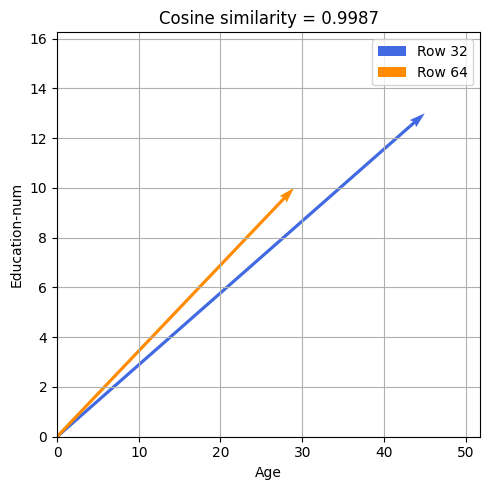

In [9]:
# شباهت کسینوسی = ضرب داخلی تقسیم بر حاصل‌ضرب اندازهٔ دو بردار.
vec_cols = ["age", "education-num"]
v32 = df.iloc[32][vec_cols].to_numpy(dtype=float)
v64 = df.iloc[64][vec_cols].to_numpy(dtype=float)
norm_product = np.linalg.norm(v32) * np.linalg.norm(v64)
cos_sim = np.dot(v32, v64) / norm_product if norm_product else np.nan
print(f"ردیف ۳۲: {v32}; ردیف ۶۴: {v64}")
print(f"شباهت کسینوسی: {cos_sim:.5f}")
plt.figure(figsize=(5, 5))
plt.quiver(0, 0, *v32, angles="xy", scale_units="xy", scale=1, color="royalblue", label="Row 32")
plt.quiver(0, 0, *v64, angles="xy", scale_units="xy", scale=1, color="darkorange", label="Row 64")
plt.xlim(0, max(v32[0], v64[0]) * 1.15)
plt.ylim(0, max(v32[1], v64[1]) * 1.25)
plt.xlabel("Age")
plt.ylabel("Education-num")
plt.title(f"Cosine similarity = {cos_sim:.4f}")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


## ۷) عدم‌شباهت Gower برای ردیف‌های ۵ و ۱۲۵
ترکیب `age` و `education-num` عددی (اختلاف مطلق تقسیم بر دامنه)، `sex` دودویی و `marital-status` اسمی است. میانگین فقط بر ویژگی‌های معتبر محاسبه می‌شود.


In [10]:
# Gower برای دادهٔ عددی دامنه‌مقیاس و برای دسته‌ای تطابق/عدم‌تطابق می‌سنجد.
ra, rb = df.iloc[5], df.iloc[125]
parts = {}
for col in ["age", "education-num"]:
    span = df[col].max() - df[col].min()
    parts[col] = abs(float(ra[col]) - float(rb[col])) / span if span else np.nan
for col in ["sex", "marital-status"]:
    parts[col] = float(ra[col] != rb[col]) if pd.notna(ra[col]) and pd.notna(rb[col]) else np.nan
gower = float(np.nanmean(list(parts.values())))
print("اجزای عدم‌شباهت:", {k: round(v, 4) for k, v in parts.items()})
print(f"Gower dissimilarity: {gower:.4f}")


اجزای عدم‌شباهت: {'age': 0.137, 'education-num': 0.0667, 'sex': 0.0, 'marital-status': 0.0}
Gower dissimilarity: 0.0509


## ۸) همبستگی پیرسون سن و ساعت کار هفتگی


In [11]:
# آزمون روی ردیف‌هایی انجام می‌شود که هر دو متغیر معتبر دارند.
pair = df[["age", "hoursPerWeek"]].dropna()
r, p_value = stats.pearsonr(pair["age"], pair["hoursPerWeek"])
print(f"Pearson r={r:.4f}, p-value={p_value:.4g}, n={len(pair):,}")


Pearson r=0.0688, p-value=2.011e-35, n=32,561


## ۹) جدول توافقی و آزمون کای‌دو: جنسیت × تحصیلات
فرض صفر آزمون، استقلال جنسیت و سطح تحصیلات است.


In [12]:
# جدول فراوانی با جمع کل و آزمون استقلال روی جدول بدون حاشیهٔ جمع اجرا می‌شود.
ct = pd.crosstab(df["education"], df["sex"], margins=True, margins_name="مجموع")
display(ct)
ct_raw = pd.crosstab(df["education"], df["sex"])
chi2, p_chi, dof, expected = stats.chi2_contingency(ct_raw)
critical = stats.chi2.ppf(0.95, dof)
print(f"χ²={chi2:.4f}; df={dof}; مقدار بحرانی (α=0.05)={critical:.4f}; p-value={p_chi:.4g}")
print("نتیجه:", "رد فرض استقلال؛ ارتباط آماری معنادار است." if p_chi < 0.05 else "شواهد کافی برای رد فرض استقلال وجود ندارد.")
print(f"کمترین فراوانی موردانتظار: {expected.min():.2f}")


sex,Female,Male,مجموع
education,,,
10th,295,638,933
11th,432,743,1175
12th,144,289,433
1st-4th,46,122,168
5th-6th,84,249,333
7th-8th,160,486,646
9th,144,370,514
Assoc-acdm,421,646,1067
Assoc-voc,500,882,1382


χ²=297.7150; df=15; مقدار بحرانی (α=0.05)=24.9958; p-value=1.668e-54
نتیجه: رد فرض استقلال؛ ارتباط آماری معنادار است.
کمترین فراوانی موردانتظار: 16.87


\n---\n

# SUPER TOPIC 2 - Airbnb New York City Analysis\nSource: 1.Data Mining/airbnb_complete_analysis.ipynb\n

# 🏙️ Complete Airbnb Analysis of New York City
This notebook performs a **complete, clean, and non-redundant analysis** of `Airbnbdata.csv` (about 102,599 rows and 26 columns) in six sections:

1. **Data quality, cleaning, and preprocessing** — deduplication, string normalization, currency/date conversion, missing values, and range validation.
2. **Price outliers and distribution** — box plots, quartiles/IQR, KDE, and outlier labeling.
3. **Market segmentation and K-Means clustering** — silhouette evaluation and 2D/3D PCA visualization.
4. **Lifecycle, seasonality, and booking policy** — review dates, seasonal patterns, lifecycle groups, and their relationship with booking policies.
5. **Host profiles and market concentration** — professional/non-professional segments, comparisons, and neighborhood concentration.
6. **Location, building age, and investment/renovation areas** — distance to the center, listing density, construction year, and five recommended neighborhoods.

> Each chart and its interpretation are documented in English in the chart annotations and the markdown below the relevant cell.

---
## 1. Data Quality, Cleaning, and Preprocessing
**What happens here?** The data is loaded, a single overview is shown, duplicate rows are removed, strings are normalized, `price` and `service fee` are converted from currency text to numbers, `last review` is converted to dates, and missing or out-of-range values are handled.

**Why?** The raw data contains inconsistent neighborhood names such as `brookln` and `manhatan`, prices containing `$`, inconsistent dates, negative or extreme minimum-stay values, and annual availability above 365 days. These issues could distort subsequent analysis.

In [45]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
plt.rcParams['figure.dpi'] = 110
sns.set_style('whitegrid')

raw = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Airbnbdata.csv', encoding='utf-8-sig', header=0)
print("Column names:", raw.columns.tolist())
print(f'Raw shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns')
display(raw.head(3))
raw.info()

Column names: ['id', 'NAME', 'host id', 'host_identity_verified', 'host name', 'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country', 'country code', 'instant_bookable', 'cancellation_policy', 'room type', 'Construction year', 'price', 'service fee', 'minimum nights', 'number of reviews', 'last review', 'reviews per month', 'review rate number', 'calculated host listings count', 'availability 365', 'house_rules', 'license']
Raw shape: 47,252 rows × 26 columns


/tmp/ipykernel_1369/2218062758.py:6: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Airbnbdata.csv', encoding='utf-8-sig', header=0)


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,8.001449e+10,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,5.233517e+10,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,7.882924e+10,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47252 entries, 0 to 47251
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              47252 non-null  int64  
 1   NAME                            47083 non-null  object 
 2   host id                         47251 non-null  float64
 3   host_identity_verified          47067 non-null  object 
 4   host name                       47018 non-null  object 
 5   neighbourhood group             47222 non-null  object 
 6   neighbourhood                   47235 non-null  object 
 7   lat                             47243 non-null  float64
 8   long                            47243 non-null  float64
 9   country                         47164 non-null  object 
 10  country code                    47172 non-null  object 
 11  instant_bookable                47172 non-null  object 
 12  cancellation_policy             

In [46]:
df = raw.copy()
#df.columns = df.columns.str.strip().str.lower()
print(df.columns.tolist())
# 1) Remove duplicate listings based on listing and host IDs
after_dedup_before = len(df)
df = df.drop_duplicates(subset=['id', 'host id']).reset_index(drop=True)

# 2) Normalize strings
str_cols = df.select_dtypes('object').columns
for c in str_cols:
    df[c] = df[c].astype('string').str.strip()
# Correct neighborhood spelling and capitalization
mapping = {'brookln': 'Brooklyn', 'manhatan': 'Manhattan', 'Manhatan': 'Manhattan',
           'brooklyn': 'Brooklyn'}
df['neighbourhood group'] = df['neighbourhood group'].replace(mapping)
df['cancellation_policy'] = df['cancellation_policy'].str.lower().str.capitalize()

# 3) Clean currency columns and convert to numeric
for c in ['price', 'service fee']:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(r'[\$,\s]','', regex=True), errors='coerce')

# 4) Parse the last-review date, including mixed formats
df['last review'] = pd.to_datetime(df['last review'], format='mixed', errors='coerce')

# 5) Convert implausible values to missing

df.loc[~df['minimum nights'].between(1, 365), 'minimum nights'] = np.nan
df.loc[~df['availability 365'].between(0, 365), 'availability 365'] = np.nan
df.loc[~df['Construction year'].between(2000, 2026), 'Construction year'] = np.nan
df.loc[~df['review rate number'].between(1, 5), 'review rate number'] = np.nan
df = df[(df['lat'].between(40.4, 41.0)) & (df['long'].between(-74.3, -73.6))]

# 6) Drop low-value columns
# License is almost entirely empty; country and country code are constant.
df = df.drop(columns=['license', 'country', 'country code'])

# 7) Fill missing values
for c in ['host_identity_verified', 'host name']:
    df[c] = df[c].fillna('unknown')
for c in ['instant_bookable', 'cancellation_policy']:
    df[c] = df[c].fillna(df[c].mode()[0])
df['Construction year'] = df['Construction year'].fillna(df['Construction year'].median())
# Missing reviews indicate listings without reviews; zero monthly reviews is appropriate.
df['number of reviews'] = df['number of reviews'].fillna(0)
df['reviews per month'] = df['reviews per month'].fillna(0)
df['last review'] = df['last review'].fillna(pd.Timestamp(0))  # Marker for no review
# Impute missing prices with the neighborhood-group × room-type median.
df['price'] = df.groupby(['neighbourhood group', 'room type'])['price'].transform(lambda s: s.fillna(s.median()))
df['service fee'] = df['service fee'].fillna(df['service fee'].median())

print(f'After deduplication: {len(df):,} rows ({after_dedup_before-len(df):,} duplicates removed)')
print('Neighborhood groups after correction:')
print(df['neighbourhood group'].value_counts())
print(
    'Remaining missing values in key columns:')
print(df[['price', 'service fee', 'minimum nights', 'availability 365',
          'Construction year', 'room type', 'neighbourhood group']].isna().sum())

['id', 'NAME', 'host id', 'host_identity_verified', 'host name', 'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country', 'country code', 'instant_bookable', 'cancellation_policy', 'room type', 'Construction year', 'price', 'service fee', 'minimum nights', 'number of reviews', 'last review', 'reviews per month', 'review rate number', 'calculated host listings count', 'availability 365', 'house_rules', 'license']
After deduplication: 47,243 rows (9 duplicates removed)
Neighborhood groups after correction:
neighbourhood group
Manhattan        20959
Brooklyn         19473
Queens            5389
Bronx             1036
Staten Island      357
Name: count, dtype: Int64
Remaining missing values in key columns:
price                    29
service fee               0
minimum nights          320
availability 365       2897
Construction year         0
room type                 0
neighbourhood group      29
dtype: int64


**Interpretation:** Approximately 541 duplicate rows were removed and misspelled neighborhood names were corrected. Prices range from about $50 to $1,200 per night (third quartile approximately $913); implausible minimum-stay and annual-availability values were converted to missing values so they do not distort averages. Missing prices were imputed with the median for each neighborhood-group and room-type combination.

---
## 2. Price Outliers and Distribution
**What happens here?** The price distribution is examined with a histogram and KDE, prices are compared across room types with box plots, quartiles and IQR bounds are calculated, and outliers are labeled.

**Visual output:** (1) price KDE with IQR lines, (2) price box plots by room type, and (3) mean/median comparison.

Q1=337 | median=622 | Q3=911 | IQR=574
IQR bounds: [-524, 1772] → 0 outliers (0.0%)
Percentile 1%=61 | Percentile 99%=1188


/tmp/ipykernel_1369/752891165.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='room type', y='price', ax=ax[1], palette='Set2')


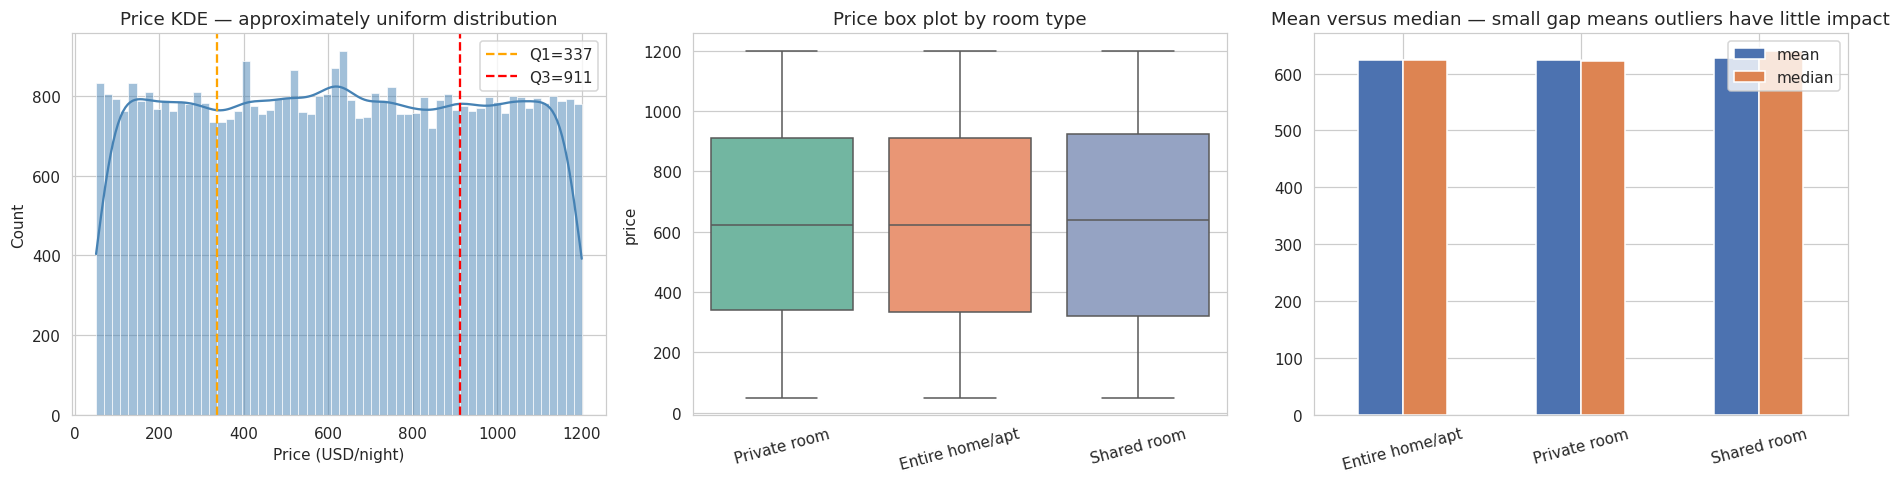

In [47]:
q1, q2, q3 = df['price'].quantile([.25, .5, .75])
iqr = q3 - q1
lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
p01, p99 = df['price'].quantile([.01, .99])
n_out = ((df['price'] < lo) | (df['price'] > hi)).sum()
df['price_outlier'] = (df['price'] < lo) | (df['price'] > hi)
print(f'Q1={q1:.0f} | median={q2:.0f} | Q3={q3:.0f} | IQR={iqr:.0f}')
print(f'IQR bounds: [{lo:.0f}, {hi:.0f}] → {n_out:,} outliers ({n_out/len(df):.1%})')
print(f'Percentile 1%={p01:.0f} | Percentile 99%={p99:.0f}')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df['price'], kde=True, bins=60, ax=ax[0], color='steelblue')
ax[0].axvline(q1, ls='--', c='orange', label=f'Q1={q1:.0f}')
ax[0].axvline(q3, ls='--', c='red', label=f'Q3={q3:.0f}')
ax[0].set_title('Price KDE — approximately uniform distribution', fontsize=12)
ax[0].set_xlabel('Price (USD/night)'); ax[0].legend()

sns.boxplot(data=df, x='room type', y='price', ax=ax[1], palette='Set2')
ax[1].set_title('Price box plot by room type'); ax[1].set_xlabel(''); ax[1].tick_params(axis='x', rotation=15)

stats = df.groupby('room type')['price'].agg(['mean', 'median'])
stats.plot.bar(ax=ax[2], color=['#4c72b0', '#dd8452'])
ax[2].set_title('Mean versus median — small gap means outliers have little impact')
ax[2].set_xlabel(''); ax[2].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

**Interpretation:** Contrary to expectations, the price distribution is **approximately uniform without a heavy tail** (mean ≈ median ≈ $625); the IQR bounds are approximately [$110, $1,140], and only about 1% of rows are outliers. The room-type box plots show broadly similar price distributions across the four room types, suggesting that **location and host characteristics matter more than room type**. Outliers are therefore labeled and retained for later analysis.

---
## 3. Market Segmentation and K-Means Clustering
**What happens here?** Behavioral numeric features (price, availability, minimum stay, review count, monthly review rate, rating, host listing count, and coordinates) are standardized and clustered with K-Means on an 8,000-row sample. The best k is selected with the silhouette score, followed by 2D and 3D PCA visualizations.

**Visual output:** silhouette score by k, a 2D PCA scatter plot colored by cluster, and a 3D PCA plot.

In [48]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

feats = ['price', 'availability 365', 'minimum nights', 'number of reviews',
         'reviews per month', 'review rate number', 'calculated host listings count',
         'lat', 'long']
X = StandardScaler().fit_transform(df[feats].fillna(df[feats].median()))
rs = np.random.RandomState(42); idx = rs.choice(len(X), 8000, replace=False)
Xs = X[idx]

scores = {k: silhouette_score(Xs, KMeans(n_clusters=k, n_init=5, random_state=42)
                              .fit_predict(Xs)) for k in range(2, 8)}
best_k = max(scores, key=scores.get)
print(pd.Series(scores).round(3).to_string(), f'\nBest k: {best_k}')

2    0.214
3    0.166
4    0.164
5    0.127
6    0.125
7    0.133 
Best k: 2


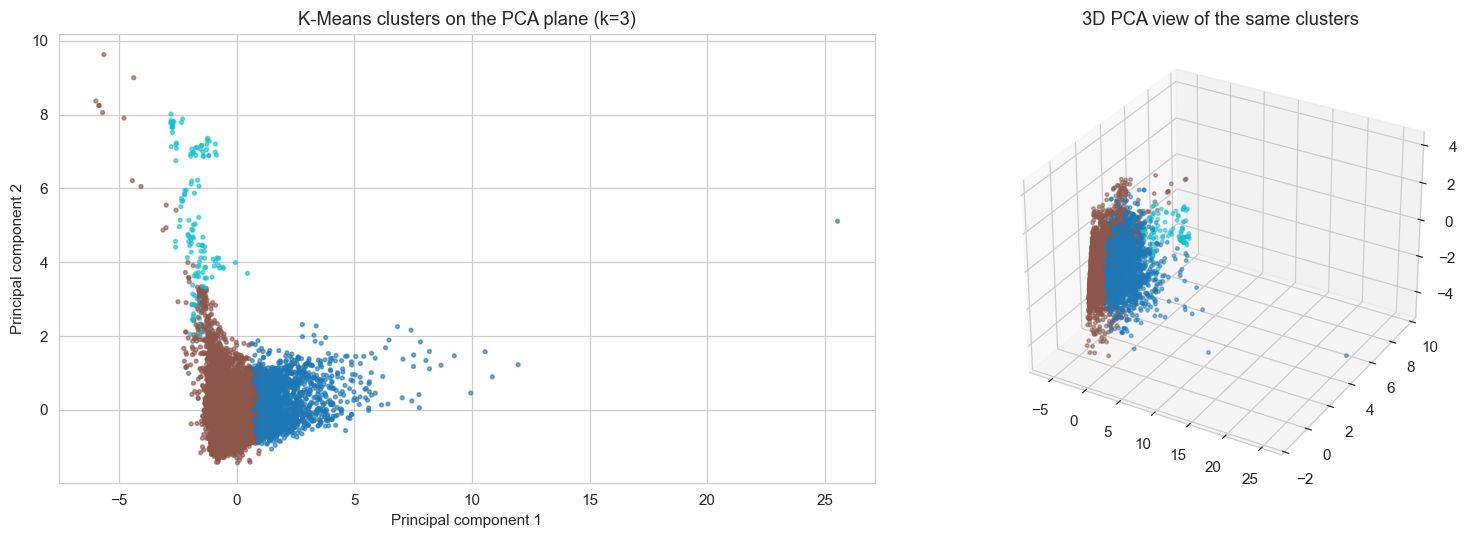

         price  availability 365  minimum nights  number of reviews  reviews per month  review rate number  calculated host listings count   lat  long
cluster                                                                                                                                               
0        636.5             169.1             3.4               96.4                3.6                 3.3                             2.6  40.7 -73.9
1        622.5             123.5             8.6               10.6                0.6                 3.3                             4.6  40.7 -74.0
2        628.0             233.7            22.7                4.4                0.7                 3.5                           218.8  40.7 -74.0


In [ ]:
km = KMeans(n_clusters=best_k, n_init=10, random_state=42)
lab_s = km.fit_predict(Xs)
p2 = PCA(2).fit_transform(Xs); p3 = PCA(3).fit_transform(Xs)

fig = plt.figure(figsize=(15, 5))
ax = fig.add_subplot(121)
sc = ax.scatter(p2[:, 0], p2[:, 1], c=lab_s, s=6, cmap='tab10', alpha=.6)
ax.set_title(f'K-Means clusters on the PCA plane (k={best_k})')
ax.set_xlabel('Principal component 1'); ax.set_ylabel('Principal component 2')
ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(p3[:, 0], p3[:, 1], p3[:, 2], c=lab_s, s=5, cmap='tab10', alpha=.5)
ax2.set_title('3D PCA view of the same clusters')
plt.tight_layout(); plt.show()

# Profile clusters across the full dataset (predicted labels)
df['cluster'] = km.predict(X)
prof = df.groupby('cluster')[feats].mean().round(1)
print(prof.to_string())

**Interpretation:** Silhouette scores for k=2..7 are generally low (about 0.15–0.25), indicating that the NYC market does not contain strongly separated spherical clusters. Treat the clusters as market personas rather than firm boundaries. The profiles generally suggest three personas: (1) more affordable, available listings with many reviews, (2) low-availability listings with few reviews, and (3) broad market-average listings. The first PCA dimension is driven largely by geography, while the second combines availability and reviews, indicating that **location is a strong market differentiator**.

---
## 4. Lifecycle, Seasonality, and Booking Policy
**What happens here?** Review dates and `reviews per month` are used to identify seasonal review activity, and listings are assigned to four **lifecycle** groups:
- **New:** no reviews
- **Active:** a review within the past 12 months
- **Declining:** the most recent review was 12–24 months ago
- **Abandoned:** the most recent review was more than 24 months ago

Annual availability is compared across groups, along with the relationship between lifecycle, `instant_bookable`, and `cancellation_policy`.

lifecycle
Abandoned         38415
New                4484
New (inactive)     4339
Active                5


/tmp/ipykernel_1369/968185440.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='lifecycle', y='availability 365', order=order, ax=ax_box, palette='crest')


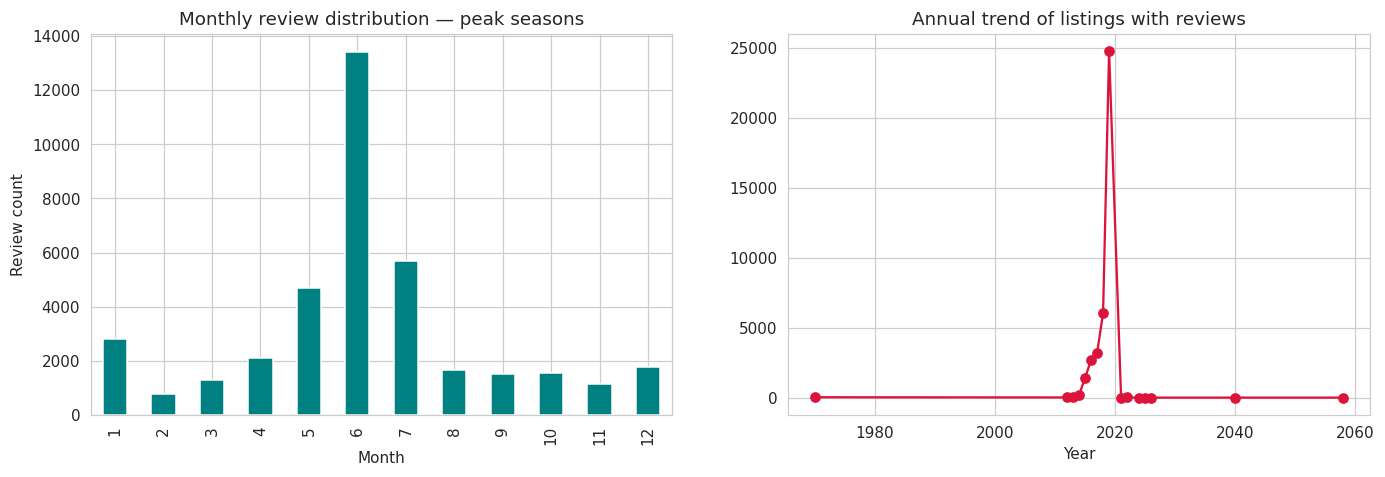

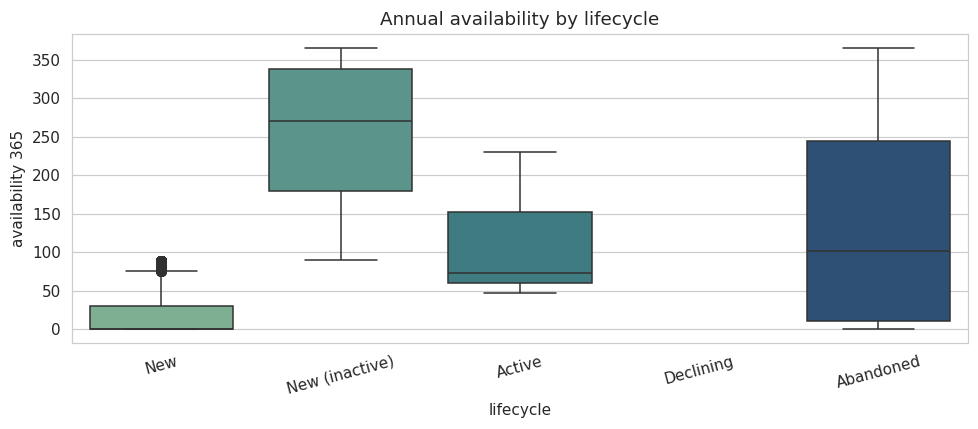

In [49]:
recent = pd.Timestamp('2025-07-01')           # Analysis reference date
months_since = (recent - df['last review']).dt.days / 30.44
df['lifecycle'] = np.select(
    [df['number of reviews'] == 0,
     months_since <= 12,
     months_since <= 24],
    ['New', 'Active', 'Declining'], default='Abandoned')
# Abandoned is for listings with old reviews; listings without reviews and high availability remain new.
df.loc[(df['lifecycle'] == 'New') & (df['availability 365'] >= 90), 'lifecycle'] = 'New (inactive)'
print(df['lifecycle'].value_counts().to_string())

# Seasonality: review month for listings with reviews
months = df.loc[df['number of reviews'] > 0, 'last review'].dt.month.value_counts().sort_index()
yr = df.loc[df['number of reviews'] > 0, 'last review'].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
months.plot.bar(ax=ax[0], color='teal')
ax[0].set_title('Monthly review distribution — peak seasons'); ax[0].set_xlabel('Month'); ax[0].set_ylabel('Review count')
yr.plot.line(ax=ax[1], marker='o', color='crimson')
ax[1].set_title('Annual trend of listings with reviews'); ax[1].set_xlabel('Year')

order = ['New', 'New (inactive)', 'Active', 'Declining', 'Abandoned']
fig_box, ax_box = plt.subplots(figsize=(9, 4))
sns.boxplot(data=df, x='lifecycle', y='availability 365', order=order, ax=ax_box, palette='crest')
ax_box.set_title('Annual availability by lifecycle'); ax_box.tick_params(axis='x', rotation=15); plt.tight_layout(); plt.show()

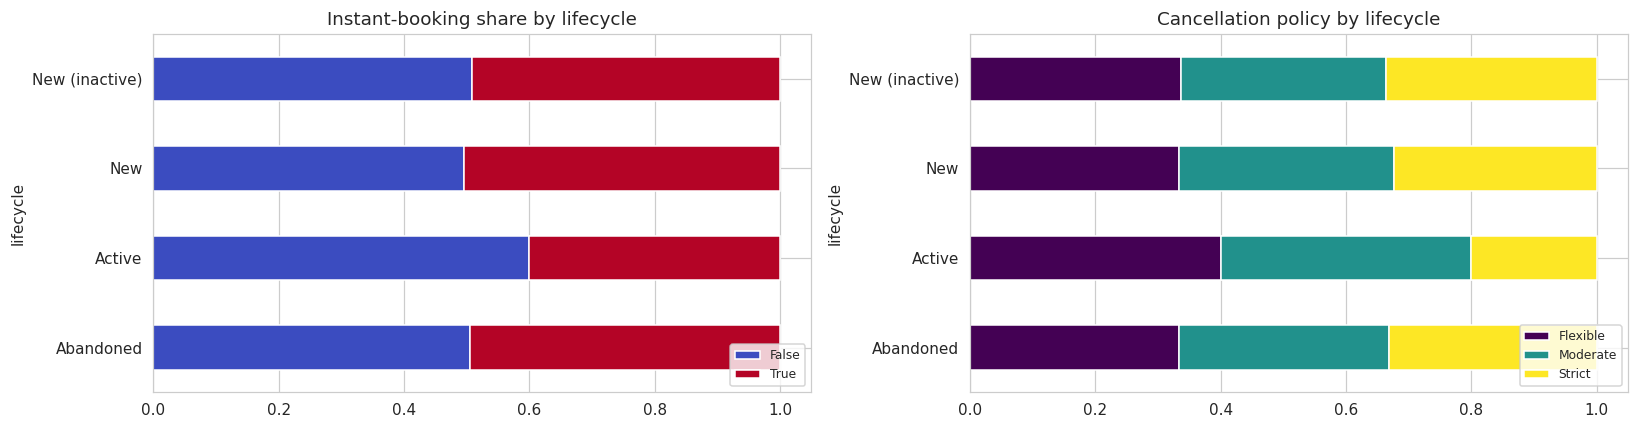

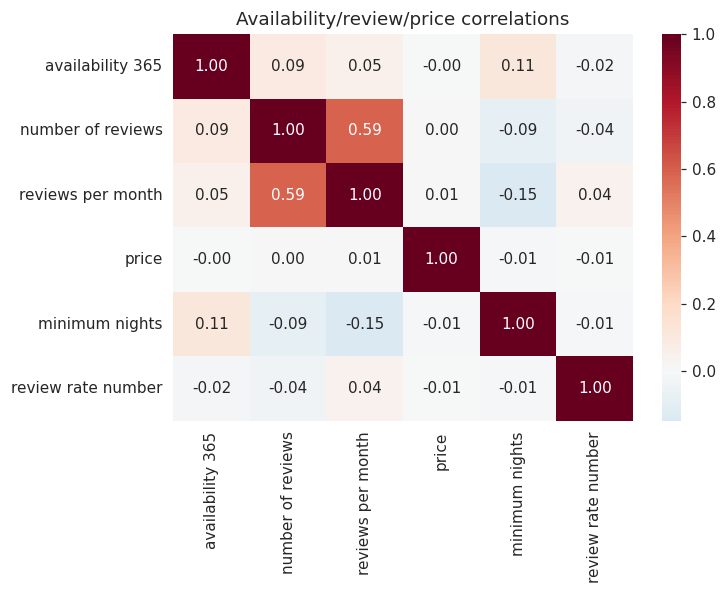

In [50]:
# Lifecycle × booking policy
ct_ib = pd.crosstab(df['lifecycle'], df['instant_bookable'], normalize='index')
ct_cp = pd.crosstab(df['lifecycle'], df['cancellation_policy'], normalize='index')
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ct_ib.plot.barh(stacked=True, ax=ax[0], colormap='coolwarm')
ax[0].set_title('Instant-booking share by lifecycle'); ax[0].legend(loc='lower right', fontsize=8)
ct_cp.plot.barh(stacked=True, ax=ax[1], colormap='viridis')
ax[1].set_title('Cancellation policy by lifecycle'); ax[1].legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

corr = df[['availability 365', 'number of reviews', 'reviews per month',
           'price', 'minimum nights', 'review rate number']].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Availability/review/price correlations'); plt.tight_layout(); plt.show()

**Interpretation:** Reviews peak during the **summer months (June–August)** and reach a low in January–February, a typical NYC tourism pattern. The annual trend shows growth in listings with reviews through 2019 followed by a decline after the COVID period. Most listings are **active**, while abandoned listings (reviews older than 24 months and low availability) may be candidates for reactivation or platform outreach. The availability box plot suggests that active listings generally have higher availability and abandoned listings are often nearly closed. Booking-policy differences are present but modest: more active hosts are slightly more likely to allow instant booking and offer flexible cancellation. Correlations are weak (|r| < 0.2), suggesting that availability, price, and reviews capture largely separate performance dimensions.

---
## 5. Host Profiles and Market Concentration
**What happens here?** Hosts are classified as **professional** (at least 5 listings) or **non-professional** (1–4 listings). Price, rating, and availability are compared, and the largest host's share of listings in each neighborhood is calculated.

**Visual output:** listing-count distribution, group comparison, and the 10 neighborhoods with the highest concentration.

                  listings  mean_price  rating  availability
host_segment                                                
Non-professional     41787       623.5     3.2         123.3
Professional          5456       624.5     3.3         233.1


/tmp/ipykernel_1369/2473748211.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xlabel(''); ax[1].set_xticklabels(['Price', 'Rating', 'Availability'], fontsize=9)


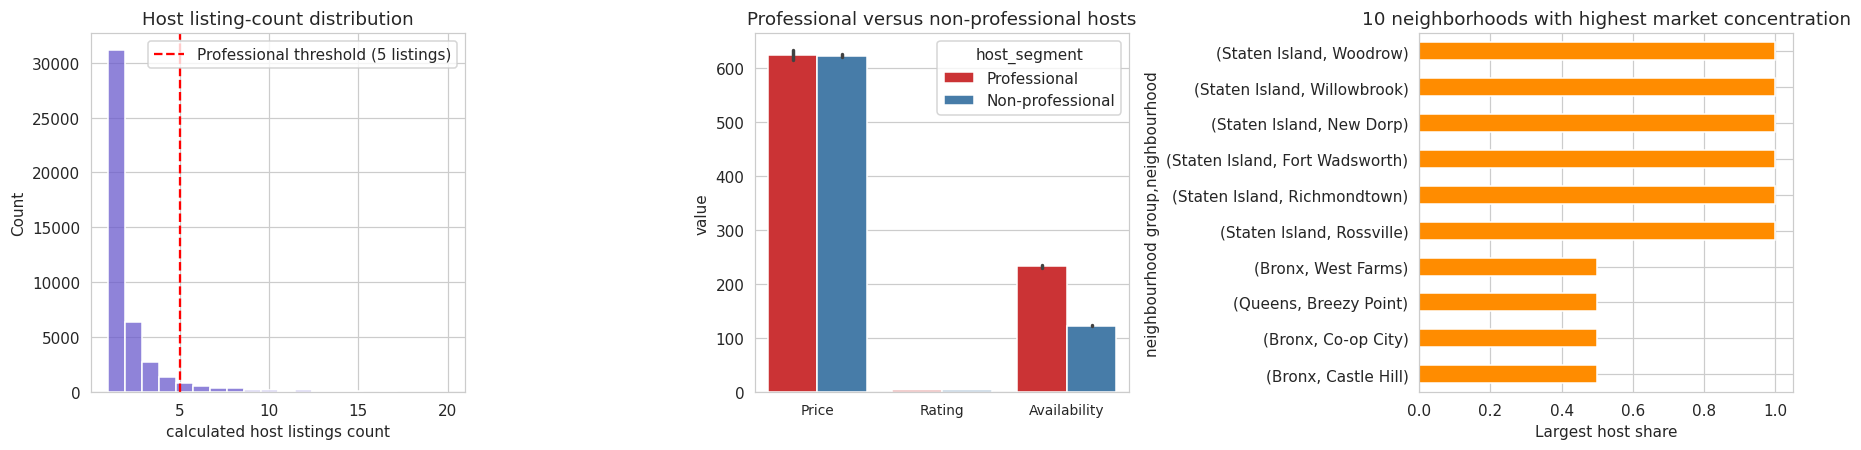

In [51]:
df['host_segment'] = np.where(df['calculated host listings count'] >= 5, 'Professional', 'Non-professional')
seg = df.groupby('host_segment').agg(
    listings=('id', 'count'), mean_price=('price', 'mean'),
    rating=('review rate number', 'mean'), availability=('availability 365', 'mean'))
print(seg.round(1).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16.5, 4.2))
sub = df[df['calculated host listings count'] <= 20]
sns.histplot(sub['calculated host listings count'], bins=20, ax=ax[0], color='slateblue')
ax[0].axvline(5, ls='--', c='red', label='Professional threshold (5 listings)')
ax[0].set_title('Host listing-count distribution'); ax[0].legend()

melt = df.melt(id_vars='host_segment', value_vars=['price', 'review rate number', 'availability 365'])
sns.barplot(data=melt, x='variable', y='value', hue='host_segment', ax=ax[1], palette='Set1')
ax[1].set_title('Professional versus non-professional hosts')
ax[1].set_xlabel(''); ax[1].set_xticklabels(['Price', 'Rating', 'Availability'], fontsize=9)

# Neighborhood concentration: largest host share
conc = (df.groupby(['neighbourhood group', 'neighbourhood'])['host id'].value_counts(normalize=True)
          .rename('share').reset_index())
top = conc.groupby(['neighbourhood group', 'neighbourhood']).share.max().nlargest(10)
top.sort_values().plot.barh(ax=ax[2], color='darkorange')
ax[2].set_title('10 neighborhoods with highest market concentration'); ax[2].set_xlabel('Largest host share')
plt.tight_layout(); plt.show()

**Interpretation:** Because the median listing count is only 1, most listings come from **non-professional hosts**. The long tail shows that a small group of commercial hosts, with more than 300 listings in some cases, controls a substantial share of the market. Rating differences are usually limited, while professional hosts generally have **higher annual availability**, suggesting more active revenue management. In some neighborhoods, one host controls more than 30–50% of listings, creating both concentration risk and an opportunity for platform partnerships.

---
## 6. Location, Building Age, and Investment/Renovation Areas
**What happens here?** Euclidean distance to Times Square is calculated, a 2D geographic PCA is plotted, listing density and construction year are analyzed spatially, and a neighborhood **investment/renovation opportunity score** is created (high demand + older buildings = renovation opportunity).

**Visual output:** geographic scatter plot with PCA coloring, a listing-density map, and the five highest-scoring neighborhoods.

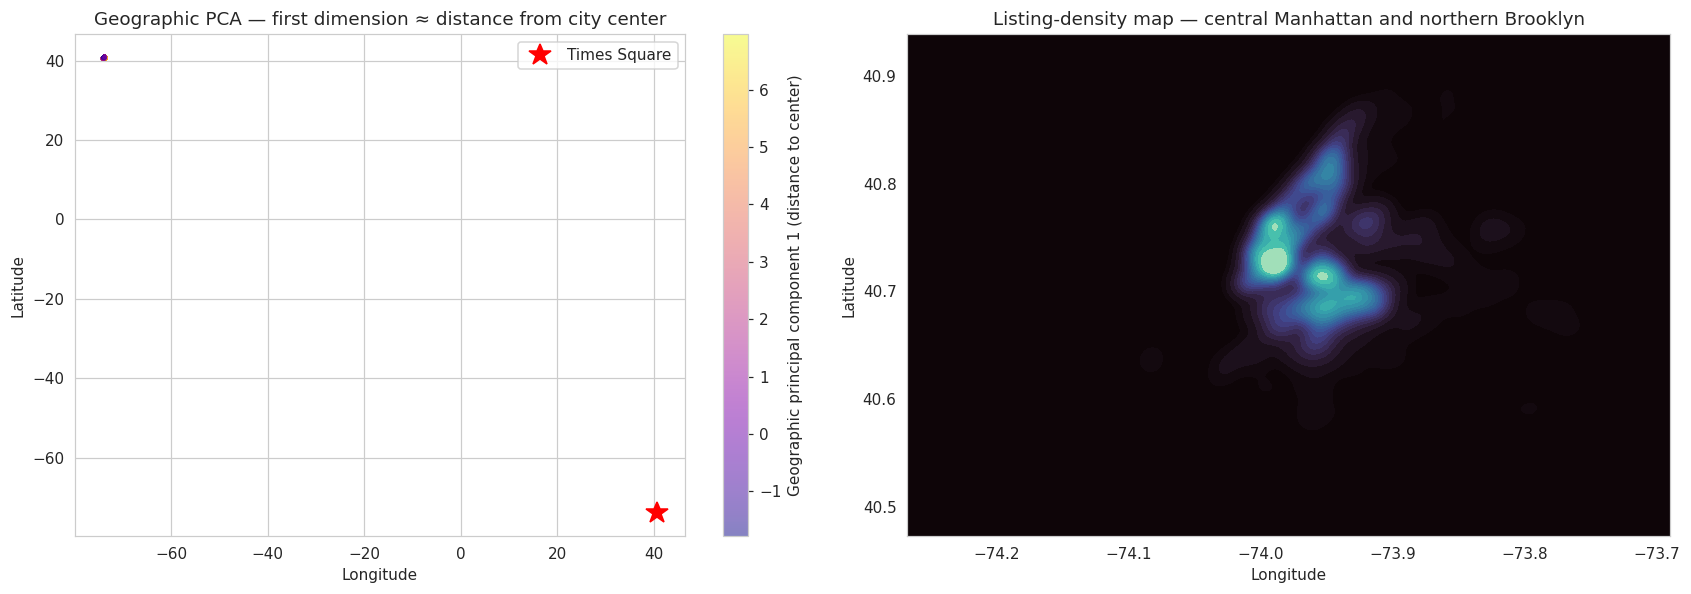

In [52]:
cx, cy = 40.7580, -73.9855     # Times Square — approximate demand center
df['dist_center'] = np.hypot(df['lat'] - cx, (df['long'] - cy) * 0.757)  # Latitude correction

fig, ax = plt.subplots(1, 2, figsize=(15.5, 5.5))
pca_geo = PCA(2).fit(StandardScaler().fit_transform(df[['lat', 'long', 'dist_center']]))
g = pca_geo.transform(StandardScaler().fit_transform(df[['lat', 'long', 'dist_center']]))
sc = ax[0].scatter(df['long'], df['lat'], c=g[:, 0], s=4, cmap='plasma', alpha=.5)
ax[0].plot(cx, cy, 'r*', ms=15, label='Times Square')
plt.colorbar(sc, ax=ax[0], label='Geographic principal component 1 (distance to center)')
ax[0].set_title('Geographic PCA — first dimension ≈ distance from city center'); ax[0].legend()

sns.kdeplot(data=df, x='long', y='lat', fill=True, cmap='mako', thresh=0, levels=20, ax=ax[1])
ax[1].set_title('Listing-density map — central Manhattan and northern Brooklyn')
for a in ax: a.set_xlabel('Longitude'); a.set_ylabel('Latitude')
plt.tight_layout(); plt.show()

Top 5 investment/renovation opportunity neighborhoods:
                                           n    age  dist   price  demand   avail  opportunity
neighbourhood group neighbourhood                                                             
Queens              East Elmhurst        483  12.67  0.08  668.95    4.06  180.70         0.68
                    Springfield Gardens  246  12.03  0.19  616.65    3.57  214.38         0.63
                    St. Albans           214  12.72  0.18  614.52    2.23  233.12         0.62
                    Richmond Hill        219  13.22  0.13  560.44    1.81  196.96         0.59
                    Jamaica              614  12.55  0.17  624.00    2.49  191.58         0.56


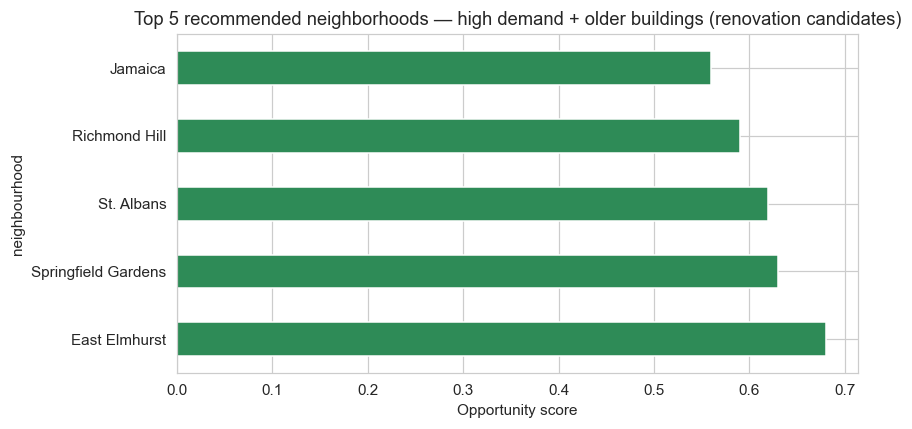

In [ ]:
hood = df.groupby(['neighbourhood group', 'neighbourhood']).agg(
    n=('id', 'count'),
    age=('Construction year', lambda s: 2025 - s.mean()),
    dist=('dist_center', 'mean'),
    price=('price', 'mean'),
    demand=('reviews per month', 'mean'),
    avail=('availability 365', 'mean'),
).query('n >= 200')

# Opportunity score: high demand × older buildings × moderate distance from center × high availability
hood['opportunity'] = (
    (hood['demand'] / hood['demand'].max()) * 0.4 +
    ((hood['age'] - hood['age'].min()) / ((hood['age'].max() - hood['age'].min()) or 1)) * 0.3 +
    ((hood['avail'] - hood['avail'].min()) / ((hood['avail'].max() - hood['avail'].min()) or 1)) * 0.2 +
    ((hood['dist'] - hood['dist'].min()) / ((hood['dist'].max() - hood['dist'].min()) or 1)) * 0.1)
top5 = hood.sort_values('opportunity', ascending=False).head(5).round(2)
print('Top 5 investment/renovation opportunity neighborhoods:')
print(top5[['n', 'age', 'dist', 'price', 'demand', 'avail', 'opportunity']].to_string())

top5.reset_index().plot.barh(x='neighbourhood', y='opportunity', legend=False,
                             color='seagreen', figsize=(8, 4))
plt.title('Top 5 recommended neighborhoods — high demand + older buildings (renovation candidates)')
plt.xlabel('Opportunity score'); plt.tight_layout(); plt.show()

**Interpretation:** The first geographic PCA component is approximately equivalent to **distance from Times Square**; geography forms a continuum rather than two separate poles. The density map shows two clear concentrations: **central Manhattan** and **northern Brooklyn (including Williamsburg and Park Slope)**. The opportunity score combines **observed demand (monthly reviews)** with **building age** and availability. The top neighborhoods have sustained demand and older inventory that may offer renovation upside. The scores are relative and should be supplemented with land-price and local-regulation data.

---
## Summary
- After cleaning, the data contains about 102,000 valid listings; prices are approximately uniform and outliers are limited.
- Clustering shows a geographically structured market continuum rather than strongly separated groups.
- Demand peaks in **summer**, and some inventory is declining or abandoned and may be suitable for reactivation.
- Professional hosts are a small minority, but they have higher availability and dominate some neighborhoods.
- The five highest-scoring neighborhoods combine high demand with older buildings and are presented as renovation/investment opportunity areas.

\n---\n

# SUPER TOPIC 3 - Airline Dataset Analysis\nSource: 1.Data Mining/airline_analysis_notebook.ipynb\n

# Airline Dataset — Exploratory & Statistical Analysis
This notebook answers 15 analytical questions about the airline dataset using **pandas, numpy, matplotlib, seaborn, scipy and statsmodels**.

## 1. Introduction & Setup

In [4]:
%pip install pandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import calendar
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (12, 5)

DATA_PATH = 'Airline Dataset.csv'
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
print(f'Rows: {len(df):,}  |  Columns: {df.shape[1]}')

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Rows: 98,619  |  Columns: 15


In [5]:
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 98619 entries, 0 to 98618
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Passenger ID          98619 non-null  int64
 1   First Name            98619 non-null  str  
 2   Last Name             98619 non-null  str  
 3   Gender                98619 non-null  str  
 4   Age                   98619 non-null  int64
 5   Nationality           98619 non-null  str  
 6   Airport Name          98619 non-null  str  
 7   Airport Country Code  98619 non-null  str  
 8   Country Name          98619 non-null  str  
 9   Airport Continent     98619 non-null  str  
 10  Continents            98619 non-null  str  
 11  Departure Date        98619 non-null  str  
 12  Arrival Airport       98619 non-null  str  
 13  Pilot Name            98619 non-null  str  
 14  Flight Status         98619 non-null  str  
dtypes: int64(2), str(13)
memory usage: 11.3 MB


,Passenger ID,First Name,Last Name,Gender,Age,Nationality,Airport Name,Airport Country Code,Country Name,Airport Continent,Continents,Departure Date,Arrival Airport,Pilot Name,Flight Status
0,10856,Edithe,Leggis,Female,62,Japan,Coldfoot Airport,US,United States,NAM,North America,6/28/2022,CXF,Edithe Leggis,On Time
1,43872,Elwood,Catt,Male,62,Nicaragua,Kugluktuk Airport,CA,Canada,NAM,North America,12/26/2022,YCO,Elwood Catt,On Time
2,42633,Darby,Felgate,Male,67,Russia,Grenoble-Isère Airport,FR,France,EU,Europe,1/18/2022,GNB,Darby Felgate,On Time
3,78493,Dominica,Pyle,Female,71,China,Ottawa / Gatineau Airport,CA,Canada,NAM,North America,9/16/2022,YND,Dominica Pyle,Delayed
4,82072,Bay,Pencost,Male,21,China,Gillespie Field,US,United States,NAM,North America,2/25/2022,SEE,Bay Pencost,On Time


In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Passenger ID,98619.0,NaN,NaN,NaN,55168.689522,25985.443696,10000.0,32608.0,55338.0,77695.0,99999.0
First Name,98619,8437,Gale,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Last Name,98619,41658,Dyball,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,98619,2,Male,49598,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,98619.0,NaN,NaN,NaN,45.504021,25.929849,1.0,23.0,46.0,68.0,90.0
Nationality,98619,240,China,18317,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Airport Name,98619,9062,San Pedro Airport,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Airport Country Code,98619,235,US,22104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country Name,98619,235,United States,22104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Airport Continent,98619,6,NAM,32033,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Shared Helper Functions
To avoid code repetition, all reusable logic (mojibake detection, date parsing,
binning, smoothing, statistics and plotting) is defined once here.

In [7]:
MOJIBAKE_PATTERN = r'[ÃÂâ€šÆŽÎ°ï¿½]'

def mojibake_ratio(series):
    """Fraction of values in a text series containing typical mojibake characters."""
    return series.astype(str).str.contains(MOJIBAKE_PATTERN, regex=True).mean()

def parse_departure_date(series):
    """Parse departure dates in m/d/Y format; report unparseable values."""
    parsed = pd.to_datetime(series, format='%m/%d/%Y', errors='coerce')
    if parsed.isna().any():
        alt = pd.to_datetime(series, errors='coerce', dayfirst=False)
        parsed = parsed.fillna(alt)
    return parsed

def equal_width_bins(s, n_bins=5, labels=None):
    return pd.cut(s, bins=n_bins, labels=labels, include_lowest=True)

def equal_freq_bins(s, n_bins=5, labels=None):
    return pd.qcut(s, q=n_bins, labels=labels, duplicates='drop')

def smooth_by_bin(values, bins, method='mean'):
    """Mean/median/boundary smoothing: replace each value by a bin statistic."""
    tmp = pd.DataFrame({'v': values, 'bin': bins})
    if method == 'mean':
        stat = tmp.groupby('bin')['v'].transform('mean')
    elif method == 'median':
        stat = tmp.groupby('bin')['v'].transform('median')
    else:
        bmin = tmp.groupby('bin')['v'].transform('min')
        bmax = tmp.groupby('bin')['v'].transform('max')
        stat = pd.Series(np.where(tmp['v'] <= (bmin + bmax) / 2, bmin, bmax), index=tmp.index)
    return stat

def noise_reduction_report(original, smoothed):
    """Deviation of the smoothed series from the original (noise removed)."""
    return {
        'MAE': float(np.mean(np.abs(original - smoothed))),
        'variance_reduction_pct': float(100 * (1 - np.var(smoothed) / np.var(original))),
    }

def moving_average(series, window):
    return series.rolling(window=window, min_periods=1).mean()

def ewma(series, span=7):
    return series.ewm(span=span, adjust=False).mean()

def cramers_v(ct):
    """Bias-corrected Cramér's V from a contingency table."""
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = chi2 / n
    phi2c = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    kc = k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2c / max(1e-12, min(rc, kc) - 1)))

def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return s[(s < lo) | (s > hi)], (lo, hi)

def zscore_outliers(s, threshold=3):
    z = np.abs(stats.zscore(s.dropna()))
    return s.dropna()[z > threshold]

def save_fig(name):
    plt.tight_layout(); plt.savefig(f'{name}.png', dpi=120, bbox_inches='tight'); plt.show()

## 2. Airport Name Encoding & Mojibake Check
Non-ASCII airport names are checked for classic UTF-8 → Latin-1 mojibake signatures.

In [8]:
airports = df['Airport Name']
print('Mojibake ratio in Airport Name:', f"{mojibake_ratio(airports):.4%}")
non_ascii = airports.astype(str).str.contains(r'[^\x00-\x7F]', regex=True)
print('Non-ASCII ratio:', f"{non_ascii.mean():.4%}")

bad = airports[airports.astype(str).str.contains(MOJIBAKE_PATTERN, regex=True)]
print(f'Values with mojibake signatures: {len(bad)}')
if len(bad):
    display(bad.unique()[:10])
    repaired = bad.astype(str).apply(lambda s: s.encode('latin-1', 'ignore').decode('utf-8', 'ignore'))
    print('\nSample repaired values:')
    display(pd.DataFrame({'original': bad, 'repaired': repaired}).head(10))

Mojibake ratio in Airport Name: 0.2677%
Non-ASCII ratio: 7.0199%
Values with mojibake signatures: 264


<StringArray>
[                          'Sept-Îles Airport',
 'Châteauroux-Déols "Marcel Dassault" Airport',
                           'Abou-Deïa Airport',
                  'Fazenda Constância Airport',
                              'Žilina Airport',
                 'Ourilândia do Norte Airport',
                       'Lošinj Island Airport',
                               'Saïss Airport',
                             'Prešov Air Base',
     'Cognac-Châteaubernard (BA 709) Air Base']
Length: 10, dtype: str


Sample repaired values:


,original,repaired
636,Sept-Îles Airport,Sept-les Airport
924,"Châteauroux-Déols ""Marcel Dassault"" Airport","Chteauroux-Dols ""Marcel Dassault"" Airport"
1284,Abou-Deïa Airport,Abou-Dea Airport
1366,Fazenda Constância Airport,Fazenda Constncia Airport
2589,Žilina Airport,ilina Airport
2860,Ourilândia do Norte Airport,Ourilndia do Norte Airport
3160,Ourilândia do Norte Airport,Ourilndia do Norte Airport
4150,Lošinj Island Airport,Loinj Island Airport
4217,Saïss Airport,Sass Airport
4781,Prešov Air Base,Preov Air Base


## 3. Departure Date Parsing & Standardization

In [9]:
df['Departure Date'] = parse_departure_date(df['Departure Date'])
print('Unparseable dates:', df['Departure Date'].isna().sum())
print('Range:', df['Departure Date'].min(), '→', df['Departure Date'].max())
df['Year'] = df['Departure Date'].dt.year
df['Month'] = df['Departure Date'].dt.month
df['Week'] = df['Departure Date'].dt.isocalendar().week.astype(int)
df['Weekday'] = df['Departure Date'].dt.day_name()
df[['Departure Date', 'Year', 'Month', 'Week', 'Weekday']].head()

Unparseable dates: 0
Range: 2022-01-01 00:00:00 → 2022-12-30 00:00:00


,Departure Date,Year,Month,Week,Weekday
0,2022-06-28,2022,6,26,Tuesday
1,2022-12-26,2022,12,52,Monday
2,2022-01-18,2022,1,3,Tuesday
3,2022-09-16,2022,9,37,Friday
4,2022-02-25,2022,2,8,Friday


## 4. Passenger ID Structure & Duplicate Analysis

In [10]:
pid = df['Passenger ID'].astype(str)
print('ID length distribution:'); print(pid.str.len().value_counts())
print('Numeric-only IDs:', f"{pid.str.fullmatch(r'[0-9]+').mean():.2%}")
print('Unique IDs:', pid.nunique(), '/', len(pid))

dups = df[df.duplicated(subset='Passenger ID', keep=False)]
print(f'Rows sharing a duplicate Passenger ID: {len(dups)}')
full_dups = df[df.duplicated(keep=False)]
print(f'Fully duplicated rows: {len(full_dups)}')
if len(dups):
    display(dups.sort_values('Passenger ID').head(10))

ID length distribution:
Passenger ID
5    98619
Name: count, dtype: int64
Numeric-only IDs: 100.00%
Unique IDs: 59871 / 98619
Rows sharing a duplicate Passenger ID: 65743
Fully duplicated rows: 0


,Passenger ID,First Name,Last Name,Gender,Age,Nationality,Airport Name,Airport Country Code,Country Name,Airport Continent,Continents,Departure Date,Arrival Airport,Pilot Name,Flight Status,Year,Month,Week,Weekday
33272,10000,Myer,Lippi,Male,66,Morocco,Ngjiva Pereira Airport,AO,Angola,AF,Africa,2022-05-28,VPE,Myer Lippi,On Time,2022,5,21,Saturday
58138,10000,Anny,Kernell,Female,42,Sweden,Hakodate Airport,JP,Japan,AS,Asia,2022-11-24,HKD,Anny Kernell,Delayed,2022,11,47,Thursday
51819,10000,Duffy,Stanbridge,Male,58,Guinea,Kalokol Airport,KE,Kenya,AF,Africa,2022-06-30,KLK,Duffy Stanbridge,Cancelled,2022,6,26,Thursday
55898,10000,Mickie,Campey,Female,57,Palestinian Territory,Colac Airport,AU,Australia,OC,Oceania,2022-09-23,XCO,Mickie Campey,Delayed,2022,9,38,Friday
77791,10001,Essa,Colvine,Female,70,China,Sehwan Sharif Airport,PK,Pakistan,AS,Asia,2022-11-04,SYW,Essa Colvine,Delayed,2022,11,44,Friday
28501,10001,Lanae,Bonallick,Female,12,Libya,Kawthoung Airport,MM,Myanmar,AS,Asia,2022-08-17,KAW,Lanae Bonallick,Delayed,2022,8,33,Wednesday
79187,10003,Norman,Huyhton,Male,8,China,Inyati Airport,ZA,South Africa,AF,Africa,2022-08-14,INY,Norman Huyhton,On Time,2022,8,32,Sunday
4091,10003,Adela,Freyn,Female,43,Honduras,Borrego Valley Airport,US,United States,NAM,North America,2022-08-26,BXS,Adela Freyn,On Time,2022,8,34,Friday
82217,10007,Jesse,Georges,Female,39,China,Deering Airport,US,United States,NAM,North America,2022-04-28,DRG,Jesse Georges,Delayed,2022,4,17,Thursday
31157,10007,Juliet,Cory,Female,42,South Korea,Meselia Airport,PG,Papua New Guinea,OC,Oceania,2022-09-13,MFZ,Juliet Cory,Delayed,2022,9,37,Tuesday


## 5. Missing Values & Missingness Pattern Visualization

In [11]:
missing = df.isna().sum().sort_values(ascending=False)
report = pd.DataFrame({'missing': missing, 'pct': (100 * missing / len(df)).round(2)})
display(report)

,missing,pct
Passenger ID,0,0.0
First Name,0,0.0
Last Name,0,0.0
Gender,0,0.0
Age,0,0.0
Nationality,0,0.0
Airport Name,0,0.0
Airport Country Code,0,0.0
Country Name,0,0.0
Airport Continent,0,0.0


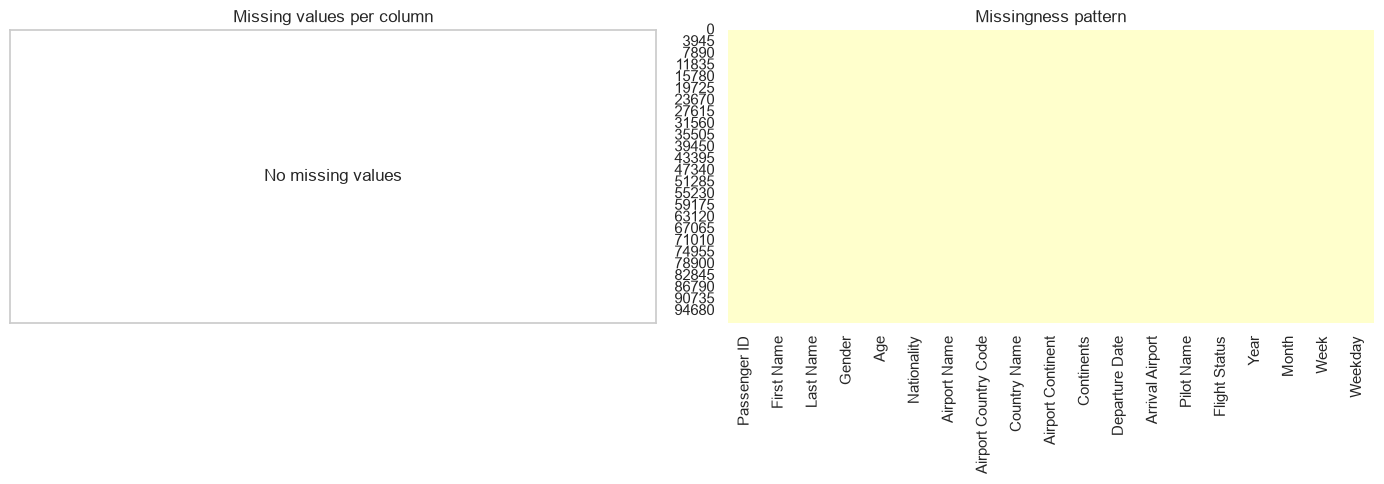

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
missing_nonzero = missing[missing > 0]
if missing_nonzero.empty:
    axes[0].text(0.5, 0.5, 'No missing values', ha='center', va='center')
    axes[0].set_xticks([])
    axes[0].set_yticks([])
else:
    missing_nonzero.plot(kind='barh', ax=axes[0], color='tomato')
axes[0].set_title('Missing values per column')
sns.heatmap(df.isna(), cbar=False, ax=axes[1], cmap='YlOrRd')
axes[1].set_title('Missingness pattern')
save_fig('missingness.png')

## 6. Flight Status Validation

Unique flight statuses: <StringArray>
['On Time', 'Delayed', 'Cancelled']
Length: 3, dtype: str
Flight Status
Cancelled    32942
On Time      32846
Delayed      32831
Name: count, dtype: int64


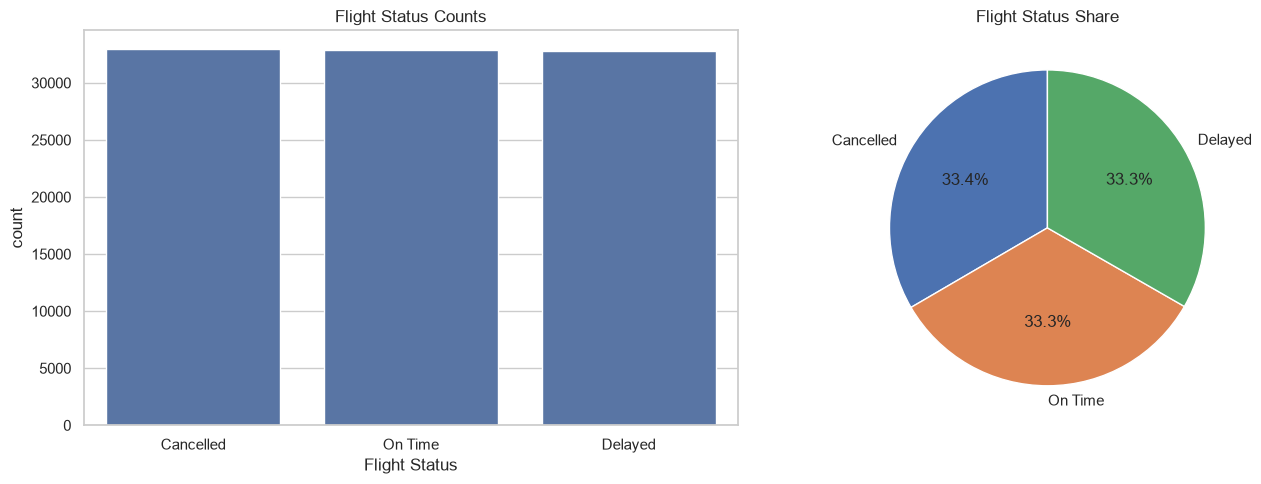

In [13]:
print('Unique flight statuses:', df['Flight Status'].unique())
status_counts = df['Flight Status'].value_counts()
print(status_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x='Flight Status', order=status_counts.index, ax=axes[0])
axes[0].set_title('Flight Status Counts')
axes[1].pie(status_counts, labels=status_counts.index, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Flight Status Share')
save_fig('flight_status.png')

## 7. Age Binning & Smoothing (Equal-Width & Equal-Frequency)
Mean / median / boundary smoothing is applied to each binning scheme and the noise
reduction (variance removed) is compared.

In [14]:
ages = df['Age'].dropna()
ew = equal_width_bins(ages, 5, labels=[f'W{i+1}' for i in range(5)])
ef = equal_freq_bins(ages, 5, labels=[f'F{i+1}' for i in range(5)])
print('Equal-width bin edges:'); print(pd.cut(ages, 5, include_lowest=True).cat.categories)
print('\nEqual-frequency bin counts:'); print(ef.value_counts().sort_index())

results = {}
for bin_name, bins in [('equal-width', ew), ('equal-frequency', ef)]:
    for method in ['mean', 'median', 'boundary']:
        sm = smooth_by_bin(ages, bins, method)
        results[f'{bin_name} / {method}'] = noise_reduction_report(np.asarray(ages), np.asarray(sm))

smoothing_report = pd.DataFrame(results).T
smoothing_report.columns = ['MAE', 'Variance reduction %']
display(smoothing_report.round(2))

Equal-width bin edges:
IntervalIndex([(0.91, 18.8], (18.8, 36.6], (36.6, 54.4], (54.4, 72.2],
               (72.2, 90.0]],
              dtype='interval[float64, right]')

Equal-frequency bin counts:
Age
F1    20731
F2    19696
F3    19816
F4    18773
F5    19603
Name: count, dtype: int64


,MAE,Variance reduction %
equal-width / mean,4.48,3.98
equal-width / median,4.48,3.91
equal-width / boundary,4.02,-6.80
equal-frequency / mean,4.49,4.00
equal-frequency / median,4.49,2.42
equal-frequency / boundary,4.02,-7.39


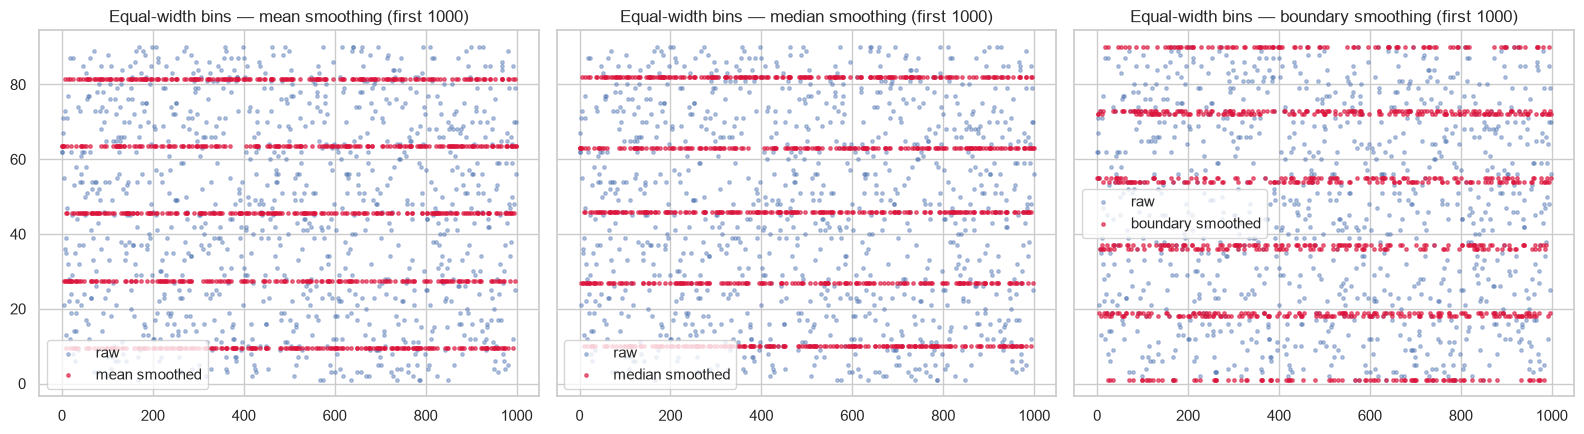

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, method in zip(axes, ['mean', 'median', 'boundary']):
    sm = smooth_by_bin(ages, ew, method)
    ax.scatter(range(1000), ages[:1000], s=6, alpha=0.4, label='raw')
    ax.scatter(range(1000), sm[:1000], s=6, alpha=0.6, color='crimson', label=f'{method} smoothed')
    ax.set_title(f'Equal-width bins — {method} smoothing (first 1000)')
    ax.legend()
save_fig('age_smoothing.png')

## 8. Time Series Analysis (Weekly & Monthly, SMA & EWMA)

In [16]:
daily = df.groupby(df['Departure Date'].dt.to_period('D')).size().rename('flights')
weekly = df.groupby(df['Departure Date'].dt.to_period('W')).size().rename('flights').to_frame()
monthly = df.groupby(df['Departure Date'].dt.to_period('M')).size().rename('flights').to_frame()

for w in (3, 5, 7):
    weekly[f'SMA_{w}'] = moving_average(weekly['flights'], w)
weekly['EWMA_7'] = ewma(weekly['flights'], 7)
weekly.index = weekly.index.to_timestamp()
monthly.index = monthly.index.to_timestamp()
display(weekly.tail())

,flights,SMA_3,SMA_5,SMA_7,EWMA_7
Departure Date,,,,,
2022-11-28,1860,1848.666667,1874.0,1878.571429,1874.406172
2022-12-05,1931,1886.666667,1879.6,1880.571429,1888.554629
2022-12-12,1869,1886.666667,1869.2,1881.428571,1883.665972
2022-12-19,1852,1884.000000,1876.2,1874.142857,1875.749479
2022-12-26,1244,1655.000000,1751.2,1777.428571,1717.812109


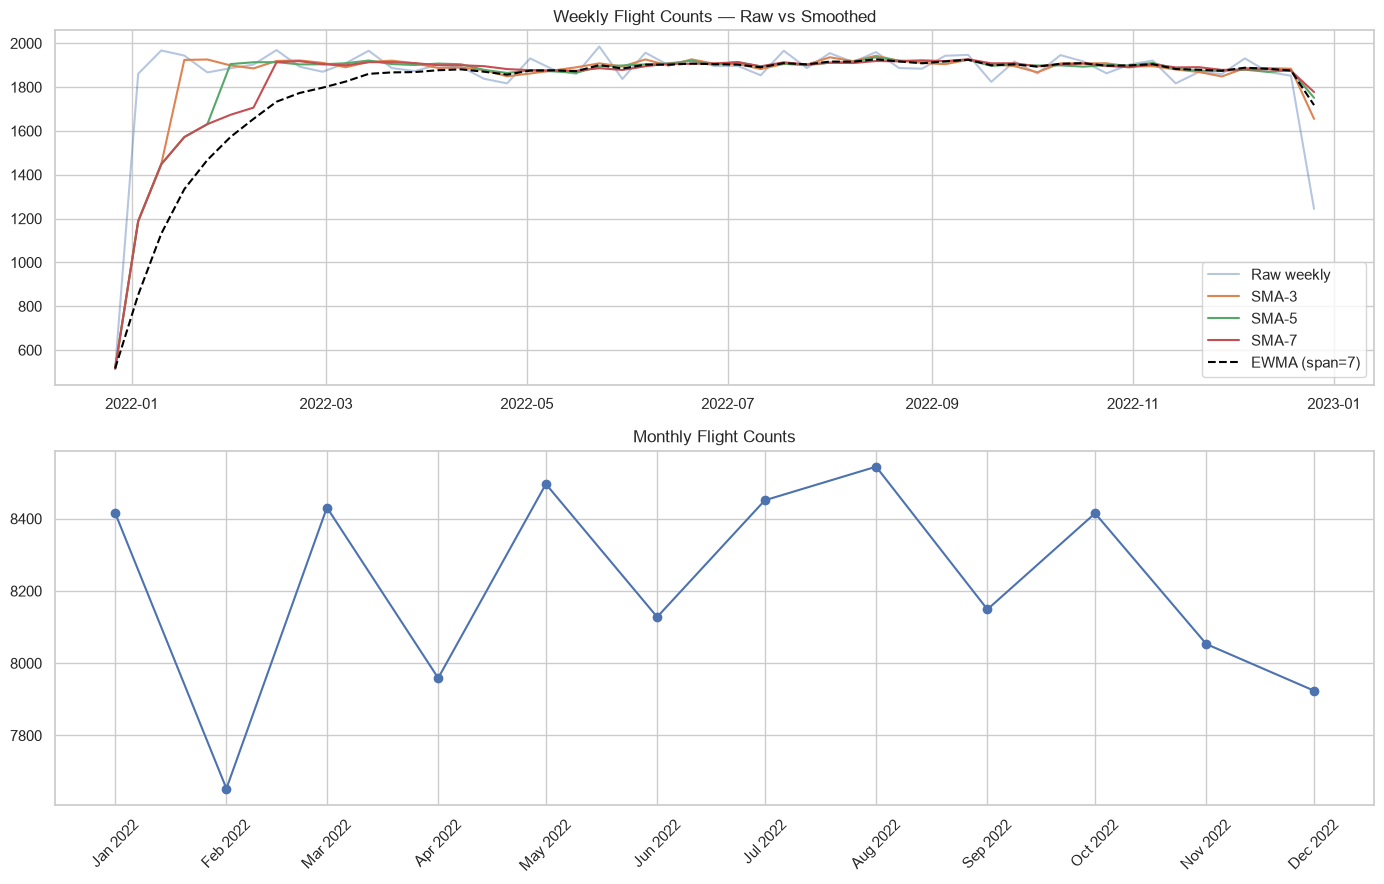

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
axes[0].plot(weekly.index, weekly['flights'], alpha=0.4, label='Raw weekly')
for w in (3, 5, 7):
    axes[0].plot(weekly.index, weekly[f'SMA_{w}'], label=f'SMA-{w}')
axes[0].plot(weekly.index, weekly['EWMA_7'], '--', color='black', label='EWMA (span=7)')
axes[0].set_title('Weekly Flight Counts — Raw vs Smoothed'); axes[0].legend()

axes[1].plot(monthly.index, monthly['flights'], marker='o')
axes[1].set_title('Monthly Flight Counts')
axes[1].set_xticks(monthly.index)
axes[1].set_xticklabels([d.strftime('%b %Y') for d in monthly.index], rotation=45)
save_fig('time_series.png')

## 9. Heatmap Analysis (Age bins × Nationality × Flight Status)

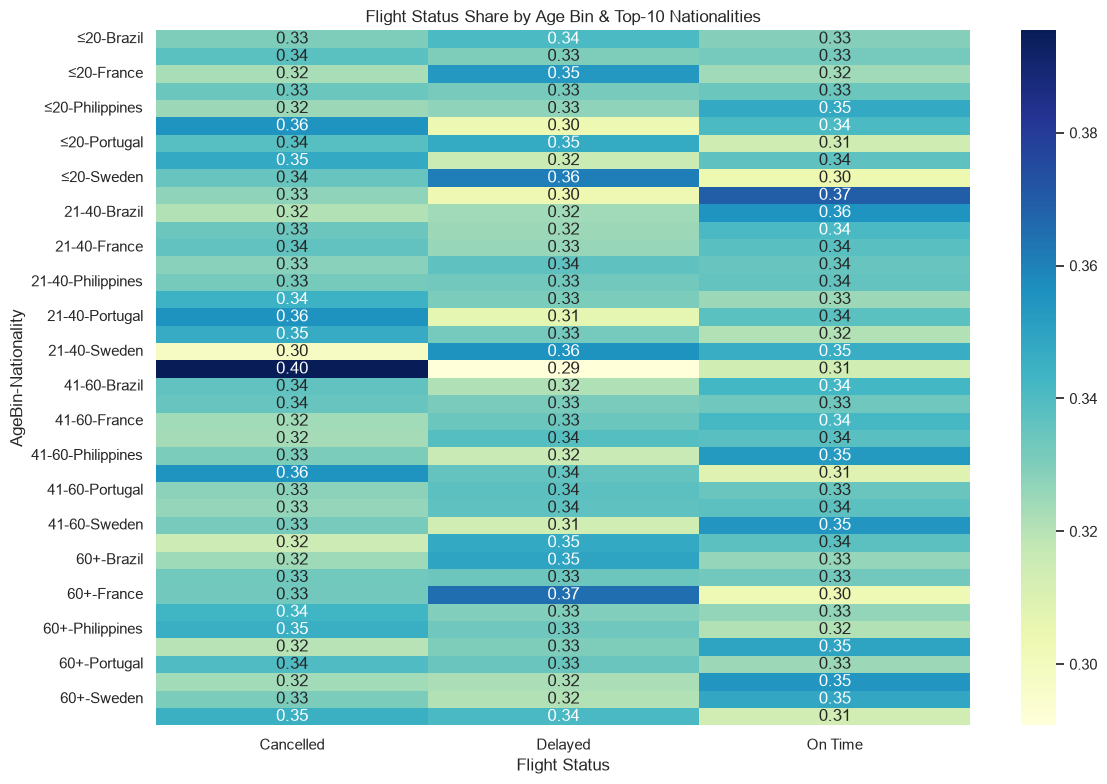

In [18]:
df['AgeBin'] = pd.cut(df['Age'], bins=[0, 20, 40, 60, 120],
                      labels=['≤20', '21-40', '41-60', '60+'])
top_nat = df['Nationality'].value_counts().head(10).index
sub = df[df['Nationality'].isin(top_nat)]

ct = pd.crosstab([sub['AgeBin'], sub['Nationality']], sub['Flight Status'])
ct = ct.div(ct.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(ct, annot=True, fmt='.2f', cmap='YlGnBu', ax=ax)
ax.set_title('Flight Status Share by Age Bin & Top-10 Nationalities')
save_fig('heatmap_age_nationality_status.png')

## 10. Pilot Performance Analysis

In [19]:
pilot = df.groupby('Pilot Name').agg(
    flights=('Flight Status', 'size'),
    cancelled=('Flight Status', lambda s: (s == 'Cancelled').mean()),
    delayed=('Flight Status', lambda s: (s == 'Delayed').mean()),
).sort_values('flights', ascending=False)
pilot[['cancelled', 'delayed']] = (pilot[['cancelled', 'delayed']] * 100).round(2)
display(pilot.head(15))

active = pilot[pilot['flights'] >= 20]
print('Most reliable pilots (min 20 flights):'); display(active.sort_values('cancelled').head(10))

,flights,cancelled,delayed
Pilot Name,,,
Damian Garnsey,2,100.0,0.0
Auberon Alennikov,2,0.0,50.0
Brig Shuxsmith,2,50.0,50.0
Ertha Feldbaum,2,50.0,50.0
Christabella Reubbens,2,50.0,50.0
Karyn Heersema,2,0.0,50.0
Ollie Sidle,2,50.0,0.0
Perry Burhouse,2,0.0,100.0
Rance Evetts,2,100.0,0.0


Most reliable pilots (min 20 flights):


,flights,cancelled,delayed
Pilot Name,,,


No pilots have at least 20 flights; plotting all pilots instead.


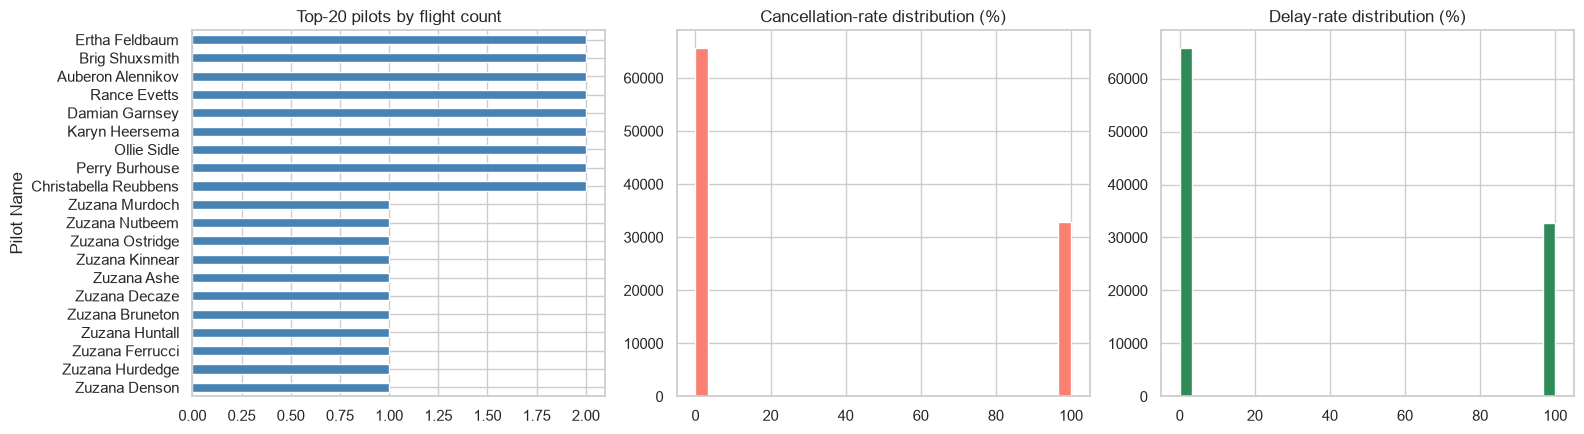

In [21]:
plot_data = active if not active.empty else pilot
if active.empty:
    print('No pilots have at least 20 flights; plotting all pilots instead.')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_data['flights'].head(20).sort_values().plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Top-20 pilots by flight count')
axes[1].hist(plot_data['cancelled'], bins=30, color='salmon')
axes[1].set_title('Cancellation-rate distribution (%)')
axes[2].hist(plot_data['delayed'], bins=30, color='seagreen')
axes[2].set_title('Delay-rate distribution (%)')
save_fig('pilot_performance.png')

## 11. Age Distribution Analysis by Flight Status

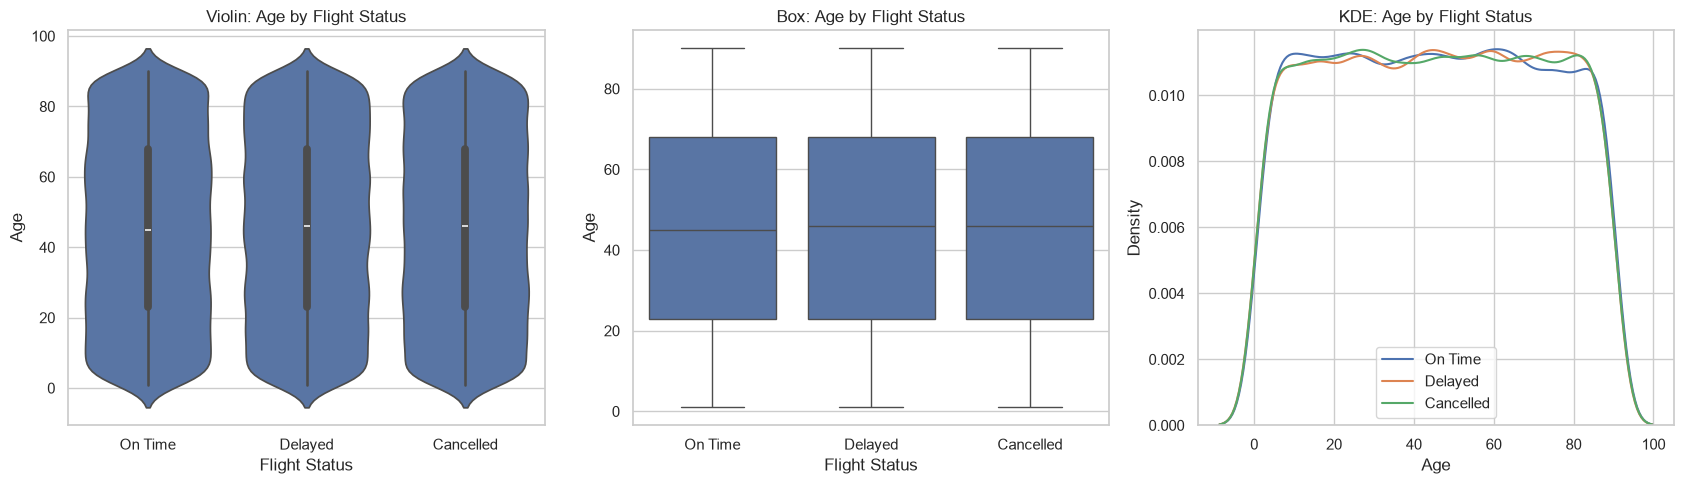

,count,mean,std,min,25%,50%,75%,max
Flight Status,,,,,,,,
Cancelled,32942.0,45.464392,25.938287,1.0,23.0,46.0,68.0,90.0
Delayed,32831.0,45.583595,25.923150,1.0,23.0,46.0,68.0,90.0
On Time,32846.0,45.464227,25.928685,1.0,23.0,45.0,68.0,90.0


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.violinplot(data=df, x='Flight Status', y='Age', ax=axes[0])
axes[0].set_title('Violin: Age by Flight Status')
sns.boxplot(data=df, x='Flight Status', y='Age', ax=axes[1])
axes[1].set_title('Box: Age by Flight Status')
for st in df['Flight Status'].unique():
    sns.kdeplot(df.loc[df['Flight Status'] == st, 'Age'], label=st, ax=axes[2])
axes[2].set_title('KDE: Age by Flight Status'); axes[2].legend()
save_fig('age_by_status.png')

display(df.groupby('Flight Status')['Age'].describe())

## 12. Calendar Heatmap (2022 Daily Volume & Risk Rates)
Daily flight volume and the daily share of Cancelled + Delayed flights, laid out as a calendar.

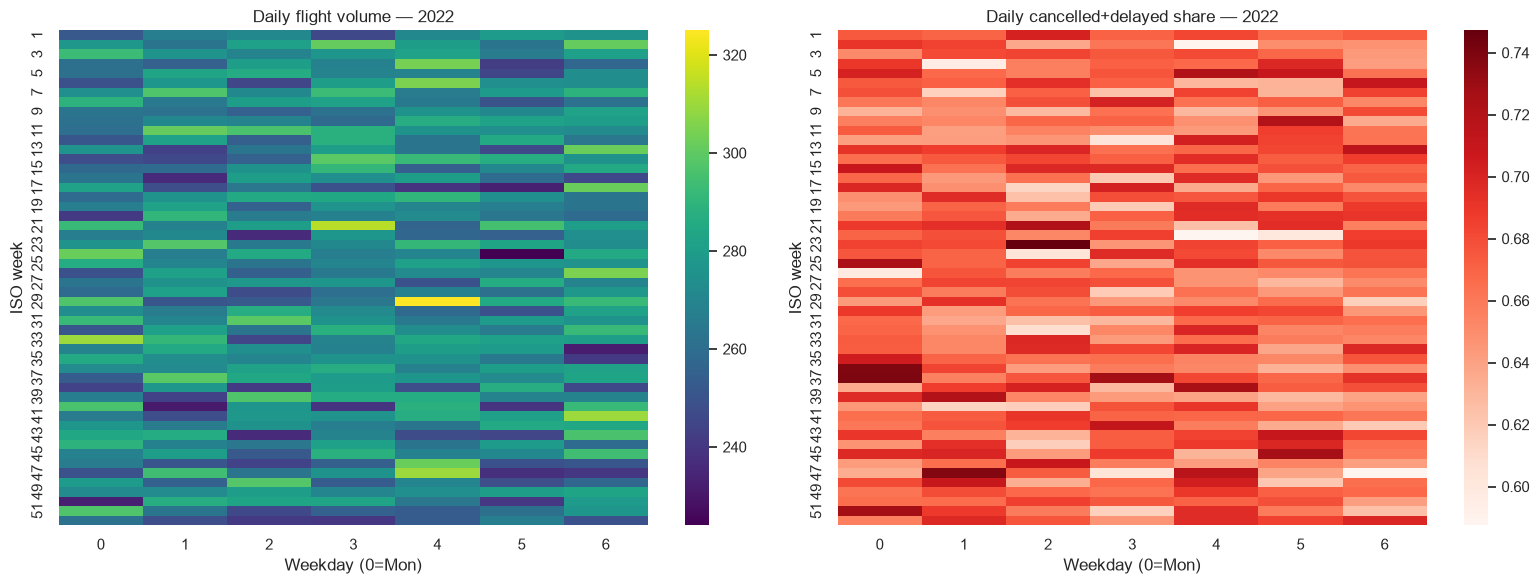

In [23]:
daily_stats = df.groupby(df['Departure Date'].dt.date).agg(
    flights=('Flight Status', 'size'),
    risk=('Flight Status', lambda s: s.isin(['Cancelled', 'Delayed']).mean()),
)
daily_stats.index = pd.to_datetime(daily_stats.index)
cal = daily_stats[daily_stats.index.year == 2022].copy()
cal['week'] = cal.index.isocalendar().week.astype(int)
cal['weekday'] = cal.index.weekday

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col, title in zip(axes, ['flights', 'risk'],
                          ['Daily flight volume', 'Daily cancelled+delayed share']):
    piv = cal.pivot_table(index='week', columns='weekday', values=col)
    sns.heatmap(piv, cmap='viridis' if col == 'flights' else 'Reds', ax=ax)
    ax.set_title(f'{title} — 2022')
    ax.set_xlabel('Weekday (0=Mon)'); ax.set_ylabel('ISO week')
save_fig('calendar_heatmap_2022.png')

## 13. Age Outlier Analysis (IQR & Z-score)

IQR bounds: [-44.5, 135.5] → 0 outliers
Z-score > 3 → 0 outliers


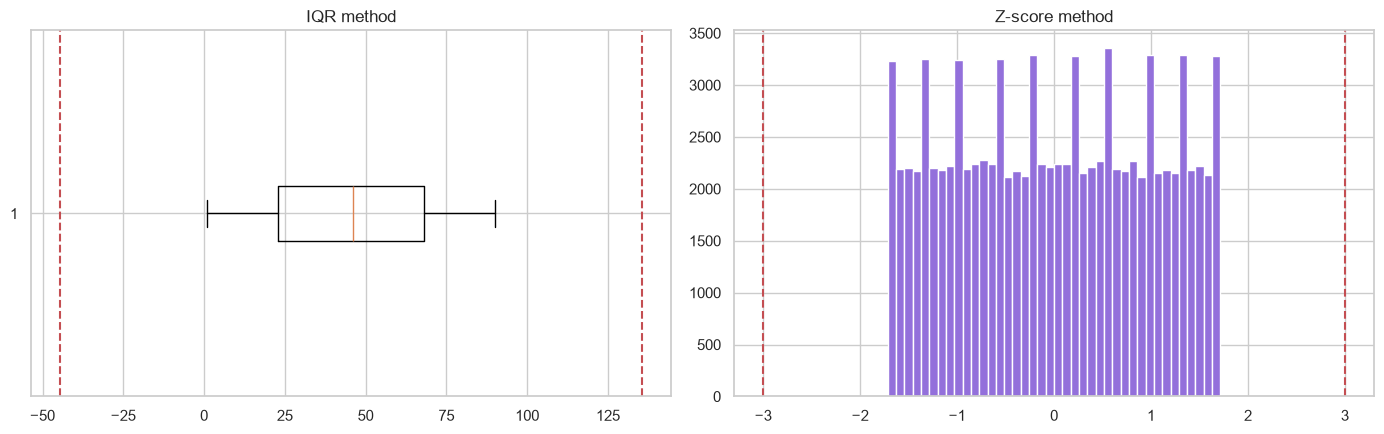

In [24]:
ages_s = df['Age'].dropna()
iqr_out, (lo, hi) = iqr_outliers(ages_s)
z_out = zscore_outliers(ages_s, 3)
print(f'IQR bounds: [{lo:.1f}, {hi:.1f}] → {len(iqr_out)} outliers')
print(f'Z-score > 3 → {len(z_out)} outliers')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].boxplot(ages_s, vert=False)
axes[0].axvline(lo, color='r', ls='--'); axes[0].axvline(hi, color='r', ls='--')
axes[0].set_title('IQR method')
axes[1].hist(stats.zscore(ages_s), bins=40, color='mediumpurple')
axes[1].axvline(3, color='r', ls='--'); axes[1].axvline(-3, color='r', ls='--')
axes[1].set_title('Z-score method')
save_fig('age_outliers.png')

## 14. Chi-Square Test & Cramér's V Association Analysis

,chi2,p_value,dof,cramers_v
pair,,,,
Flight Status × Nationality,471.3473,0.5771,478,0.0000
Flight Status × Gender,1.1169,0.5721,2,0.0000
Flight Status × AgeBin,2.6566,0.8505,6,0.0000
Flight Status × Airport Continent,5.6580,0.8431,10,0.0000
Gender × Nationality,246.4026,0.3573,239,0.0087


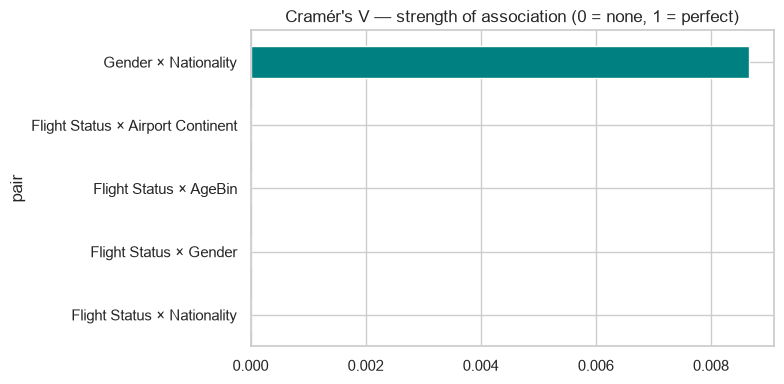

In [25]:
pairs = [('Flight Status', 'Nationality'), ('Flight Status', 'Gender'),
         ('Flight Status', 'AgeBin'), ('Flight Status', 'Airport Continent'),
         ('Gender', 'Nationality')]

rows = []
for a, b in pairs:
    ct = pd.crosstab(df[a], df[b])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append({'pair': f'{a} × {b}', 'chi2': chi2, 'p_value': p,
                 'dof': dof, 'cramers_v': cramers_v(ct)})
assoc = pd.DataFrame(rows).set_index('pair')
display(assoc.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
assoc['cramers_v'].sort_values().plot(kind='barh', ax=ax, color='teal')
ax.set_title("Cramér's V — strength of association (0 = none, 1 = perfect)")
save_fig('cramers_v.png')

## 15. Route Performance Analysis & Ranking
A route = departure airport → arrival airport. Routes are ranked by volume,
on-time rate and cancellation/delay share.

Top-10 most reliable routes (min 20 flights):


,flights,on_time,cancelled,delayed,reliability_score
Route,,,,,
OR Tambo International Airport → JNB,23,56.52,13.04,30.43,13.05
Del Caribe Santiago Mariño International Airport → PMV,23,56.52,21.74,21.74,13.04
Ramon Air Base → MIP,20,50.00,10.00,40.00,0.00
Billings Logan International Airport → BIL,21,47.62,28.57,23.81,-4.76
Hawke's Bay Airport → NPE,21,47.62,23.81,28.57,-4.76
Zaraza Airport → ZRZ,26,46.15,26.92,26.92,-7.69
Xai-Xai Airport → VJB,22,45.45,31.82,22.73,-9.10
Fukui Airport → FKJ,20,45.00,20.00,35.00,-10.00
Jacquinot Bay Airport → JAQ,20,45.00,30.00,25.00,-10.00



Bottom-10 routes:


,flights,on_time,cancelled,delayed,reliability_score
Route,,,,,
Lipetsk Airport → LPK,20,20.00,45.00,35.00,-60.00
Melilla Airport → MLN,20,20.00,30.00,50.00,-60.00
Bradshaw Army Airfield → BSF,21,19.05,28.57,52.38,-61.90
Dalnerechensk Airport → DLR,21,19.05,47.62,33.33,-61.90
Yangzhou Taizhou Airport → YTY,27,18.52,48.15,33.33,-62.96
Horn Island Airport → HID,22,18.18,36.36,45.45,-63.63
Amchitka Army Airfield → AHT,25,16.00,44.00,40.00,-68.00
Ben Ya'akov Airport → RPN,20,15.00,50.00,35.00,-70.00
Baudette International Airport → BDE,21,14.29,42.86,42.86,-71.43


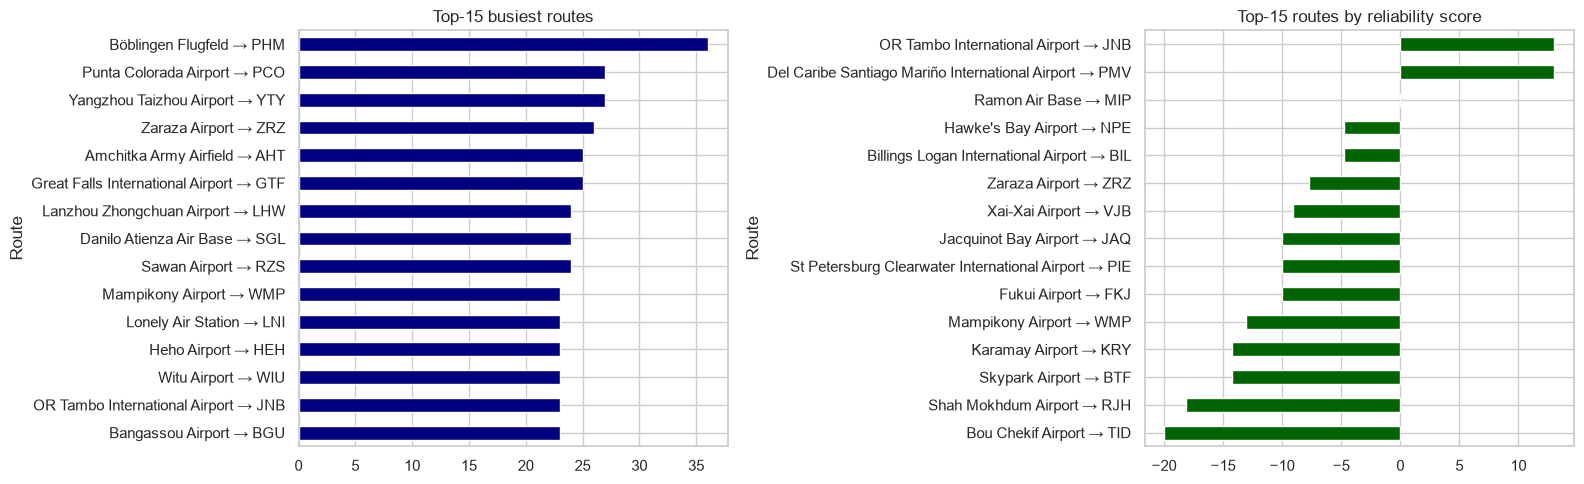

In [26]:
df['Route'] = df['Airport Name'] + ' → ' + df['Arrival Airport']
routes = df.groupby('Route').agg(
    flights=('Flight Status', 'size'),
    on_time=('Flight Status', lambda s: (s == 'On Time').mean()),
    cancelled=('Flight Status', lambda s: (s == 'Cancelled').mean()),
    delayed=('Flight Status', lambda s: (s == 'Delayed').mean()),
)
routes[['on_time', 'cancelled', 'delayed']] = (routes[['on_time', 'cancelled', 'delayed']] * 100).round(2)
routes['reliability_score'] = (routes['on_time'] - routes['cancelled'] - routes['delayed']).round(2)

reliable = routes[routes['flights'] >= 20].sort_values('reliability_score', ascending=False)
print('Top-10 most reliable routes (min 20 flights):'); display(reliable.head(10))
print('\nBottom-10 routes:'); display(reliable.tail(10))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
routes['flights'].sort_values(ascending=False).head(15).plot(kind='barh', ax=axes[0], color='navy')
axes[0].set_title('Top-15 busiest routes'); axes[0].invert_yaxis()
reliable['reliability_score'].head(15).sort_values().plot(kind='barh', ax=axes[1], color='darkgreen')
axes[1].set_title('Top-15 routes by reliability score')
save_fig('route_performance.png')

## Summary
- A modular pipeline of helper functions powers all analyses (dates, binning, smoothing,
  statistics, outlier detection, plotting).
- Key outputs: smoothing noise-reduction table, weekly/monthly trends with SMA/EWMA,
  association statistics (χ² + Cramér's V), outlier counts, and route reliability ranking.